# G5.3 — Hipótese testável: a atenção cruzada melhora a transferência geométrica?

**Hipótese científica.** Dado o mesmo Hamiltoniano de carteiras, a mesma referência geométrica QR, o mesmo treinamento de 2024 e os mesmos exemplos, uma arquitetura **encoder–decoder não autoregressiva** pode produzir correções angulares mais confiáveis do que um **encoder-only**. Investigaremos o ganho pareado em $P_\star$, energia, Hamming, calibração conformal e custo de inferência, incluindo $12C5$, ausente do treinamento.

## 1. Do portfólio à energia

**Seleção combinatória.** Para $n$ ativos e uma escolha de $k$:

$$
\underbrace{x_i\in\{0,1\}}_{\substack{\downarrow\\0:\ \text{ativo fora};\quad 1:\ \text{ativo dentro}}},\qquad
\underbrace{\sum_{i=1}^n x_i=k}_{\substack{\downarrow\\\text{cardinalidade fixa}}},\qquad
\underbrace{\Omega_{n,k}=\{x:\textstyle\sum_i x_i=k\}}_{\substack{\downarrow\\\text{bitstrings viáveis}}}.
$$

A carteira $x$ recebe a energia financeira:

$$
\boxed{
\underbrace{E_H(x)}_{\substack{\downarrow\\\text{valor a minimizar}}}
= \underbrace{\tfrac12 x^\top\Sigma x}_{\substack{\downarrow\\\text{risco quadrático}}}
-\underbrace{\mu^\top x}_{\substack{\downarrow\\\text{retorno esperado}}}
}
$$

- $\mu\in\mathbb R^n$ → retornos médios anualizados calculados **somente até a data da instância**;
- $\Sigma\in\mathbb R^{n\times n}$ → matriz de covariâncias anualizada, na mesma janela;
- $x\in\Omega_{n,k}$ → somente carteiras admissíveis entram no espectro;
- $\Omega_{n,k}$ contém $\binom nk$ bitstrings, por exemplo $\binom{12}{5}=792$.

**Enumeramos o espectro viável de energia** $\mathbf E=(E_H(x))_{x\in\Omega_{n,k}}$ e calculamos o ótimo clássico **apenas como referência física**. Esse procedimento **não** estabelece vantagem computacional quântica sobre a enumeração.

## 2. Do circuito ao estado de Dicke

O ansatz preserva o número de bits ocupados. Ele começa no estado uniforme:

$$
\underbrace{|D_k^n\rangle}_{\substack{\downarrow\\\text{Dicke, condição inicial}}}
=\underbrace{\binom nk^{-1/2}}_{\substack{\downarrow\\\text{normalização}}}
\underbrace{\sum_{x\in\Omega_{n,k}}|x\rangle}_{\substack{\downarrow\\\text{superposição de carteiras viáveis}}}.
$$

O circuito $U(\boldsymbol\phi)$ é construído **exclusivamente no Qiskit**, com
$g=k(n-k)$ parâmetros nesta família de gates. A probabilidade de cada carteira é:

$$
\underbrace{p_{\boldsymbol\phi}(x)}_{\substack{\downarrow\\\text{distribuição do circuito}}}
=\left|\underbrace{\langle x|U(\boldsymbol\phi)|x_{\mathrm{init}}\rangle}_{\substack{\downarrow\\\text{amplitude no Statevector}}}\right|^2.
$$

## 3. Da Jacobiana ao espaço tangente geométrico

Em torno dos ângulos de Dicke $\boldsymbol\phi_D$, calculamos diferenças centrais com Qiskit:

$$
\underbrace{J_{xj}}_{\substack{\downarrow\\\text{sensibilidade da carteira }x\text{ ao gate }j}}
=\left.\frac{\partial p_{\boldsymbol\phi}(x)}{\partial\phi_j}\right|_{\boldsymbol\phi_D}
\approx\frac{p_{\phi_D+h e_j}(x)-p_{\phi_D-h e_j}(x)}{2h}.
$$

Dimensões: $J\in\mathbb R^{\binom nk\times g}$, $e_j\in\mathbb R^g$, $h=10^{-4}$ nas unidades angulares normalizadas do notebook.

O espectro de $J^\top J$ define os modos geométricos:

$$
\underbrace{J^\top J}_{g\times g}
=\underbrace{V}_{g\times g}\underbrace{\Lambda}_{g\times g}\underbrace{V^\top}_{g\times g}
\quad\longrightarrow\quad
\underbrace{J_M=JV}_{\substack{\downarrow\\\text{modos de resposta das probabilidades}}}.
$$

$V$ contém autovetores ortonormais; $\Lambda$ contém autovalores que medem intensidade local dos modos.

## 4. De Legendre à direção QR

Primeiro padronizamos a energia local:

$$
\underbrace{z_x}_{\substack{\downarrow\\\text{energia padronizada}}}
=\frac{E_H(x)-\overline E}{\max(3\,\sigma_E,10^{-12})}.
$$

Construímos a matriz $F\in\mathbb R^{\binom nk\times8}$ com os polinômios $P_m(z_x)$ para $m=1,\ldots,8$, centralizando as colunas:

$$
F_{xm}=P_m(z_x)-\frac{1}{|\Omega_{n,k}|}\sum_{y\in\Omega_{n,k}}P_m(z_y).
$$

A projeção energética na geometria é:

$$
\underbrace{B}_{g\times8}=\underbrace{J_M^\top}_{g\times\binom nk}\underbrace{F}_{\binom nk\times8}
\longrightarrow\underbrace{A_{:m}=B_{:m}/\|B_{:m}\|_2}_{\substack{\downarrow\\\text{colunas normalizadas}}}
\longrightarrow\boxed{\underbrace{A=Q_HR_H}_{\substack{\downarrow\\\text{fatoração QR}}}}.
$$

Usando o coeficiente $a_{\rm 2024}$ calculado **exclusivamente no treino de 2024**, obtemos:

$$
\underbrace{q_H}_{g\times1}
=\frac{Q_H a_{\rm 2024}}{\|Q_H a_{\rm 2024}\|_2}
\quad\longrightarrow\quad
\boxed{\underbrace{\boldsymbol\phi_{QR}}_{\substack{\downarrow\\\text{inicialização geométrica}}}
=\underbrace{\boldsymbol\phi_D}_{\substack{\downarrow\\\text{Dicke}}}
+\underbrace{\rho}_{\substack{\downarrow\\\text{passo geométrico, }1.5}}
\underbrace{Vq_H}_{\substack{\downarrow\\\text{direção em coordenadas de gate}}}}.
$$

## 5. Da geometria aos dois conjuntos de tokens

**Tokens de gates** $G\in\mathbb R^{g\times25}$: um token por parâmetro; carregam direção QR, dados locais e posição combinatória $i,l,n,k$. **Tokens espectrais** $S\in\mathbb R^{16\times25}$: 16 grupos quantílicos do **mesmo espectro de energia da instância**, com estatísticas locais, globais e valores dos polinômios de Legendre. Ambos são padronizados usando **somente o treino de 2024**.

**Controle de informação:** a arquitetura encoder-only e a encoder–decoder usam **exatamente os mesmos dois conjuntos de tokens**. O espectro inclui os valores de energia dos portfólios admissíveis, o que também é necessário na construção de QR; não alimentamos à rede o índice da carteira ótima. A distinção entre os modelos é a **organização da atenção**, não a fonte de dados.

## 6. Da previsão angular à física e à avaliação

$$
\underbrace{\hat{\boldsymbol\phi}}_{\substack{\downarrow\\\text{ângulos usados no Qiskit}}}
=\underbrace{\boldsymbol\phi_{QR}}_{\substack{\downarrow\\\text{geometria fixa}}}
+\underbrace{1.2\tanh(f_\psi(G,S))}_{\substack{\downarrow\\\text{correção one-shot do Transformer}}}.
$$

A qualidade é aferida por três indicadores diferentes:

$$
\underbrace{P_\star}_{\substack{\downarrow\\\text{massa de probabilidade nos ótimos}}}
=\sum_{x\in\Omega_\star}p_{\hat\phi}(x),\quad
\underbrace{\Delta E_x}_{\substack{\downarrow\\\text{erro energético por bitstring}}}
=E_H(x)-E_0,\quad
\underbrace{d_H(x,\Omega_\star)}_{\substack{\downarrow\\\text{mínimo de trocas de bits}}}
=\min_{y\in\Omega_\star}\sum_{i=1}^n|x_i-y_i|.
$$

$E_0=\min_{x\in\Omega_{n,k}}E_H(x)$ e $\Omega_\star=\{x:E_H(x)=E_0\}$; **$d_H=0$** é ótimo, **$d_H=2$** significa trocar uma ação. Hamming e energia **não precisam ter ordenação idêntica**, apesar de compartilharem o mesmo ótimo. Os resultados de 2025–2026 não modificam pesos, escaladores, checkpoints, hiperparâmetros nem limiares conformais.

# Bloco 2 — Fluxograma e arquitetura encoder-only × encoder–decoder

O objetivo deste teste não é gerar um texto autoregressivo. O decoder prevê **todos os ângulos simultaneamente**, sem máscara triangular e sem receber ângulos ótimos anteriores. Isso preserva **one forward** na inferência.

## Fluxograma pareado (mesmas entradas, duas arquiteturas)

```text
  Hamiltoniano financeiro H = (μ,Σ)  [dados disponíveis até a data]
                         │
                         ▼
                E(x) para x em Ω(n,k)
                         │
              ┌──────────┴──────────┐
              ▼                     ▼
     Geometria por gate       Espectro dividido
    Dicke → J → Legendre     em 16 faixas quantílicas
      → QR → G [g,25]          → S [16,25]
              │                     │
              │       Mesmas fontes de informação
              ├─────────────────────┤
              │                     │
              ▼                     ▼
       [A] ENCODER-ONLY      [B] ENCODER–DECODER
       concat(G,S)          Encoder(S) → memória M
              │             Decoder(query=G, M)
        4 × self-attention       1 × encoder + 2 × decoder
              │                cada decoder: self-attn + cross-attn
         últimos g tokens              │
              │                        │
              └───────────┬────────────┘
                          ▼
                cabeça Linear(48→1)
                          ▼
                 Δφ_j=1.2 tanh(h_j)
                          ▼
                 φ_final = φ_QR+Δφ
                          ▼
                 Qiskit: U(φ_final)
                          ▼
               P★, ⟨E⟩, Hamming, shots
                          ▼
          loss de 2024 → PyTorch (SPSA angular)
          conformal 2024 → comparação 2025/26
```

## Arquitetura A: controle encoder-only

- `gate_embed`: $25\to48$; `spectrum_embed`: $25\to48$;
- concatenamos os $16$ tokens espectrais e os $g$ tokens de gates: $Z=[S;G]\in\mathbb R^{(16+g)\times48}$;
- **4 camadas encoder**, cada uma com **4 cabeças** ($d_{\rm head}=48/4=12$), feed-forward $48\to96\to48$, GELU, conexões residuais e LayerNorm;
- lemos apenas as $g$ saídas correspondentes aos gates;
- cabeça compartilhada `Linear(48,1)` e ativação $1.2\tanh$.

Esse controle usa o espectro completo **no mesmo nível de acesso informacional** que o encoder–decoder. O número de camadas foi escolhido para aproximar os totais de parâmetros, que o notebook imprime e audita.

## Arquitetura B: encoder–decoder com cross-attention

- `spectrum_embed`: $25\to48$;
- **encoder**: uma camada, com 4 cabeças, $48\to96\to48$;
- memória $M=\mathrm{Encoder}(S)\in\mathbb R^{16\times48}$;
- `gate_embed`: $25\to48$;
- **decoder**: duas camadas, cada uma com **self-attention** entre gates, **cross-attention** aos 16 tokens de memória e feed-forward $48\to96\to48$;
- **sem máscara causal**: os $g$ gates são conhecidos estruturalmente, então todos os ângulos saem juntos;
- cabeça compartilhada `Linear(48,1)`.

## Equação da atenção cruzada

$$
\underbrace{Q_h}_{g\times12}
=\underbrace{G_hW_h^Q}_{\substack{\downarrow\\\text{consultas dos gates}}},\qquad
\underbrace{K_h}_{16\times12}
=\underbrace{MW_h^K}_{\substack{\downarrow\\\text{chaves do espectro}}},\qquad
\underbrace{V_h}_{16\times12}
=\underbrace{MW_h^V}_{\substack{\downarrow\\\text{valores do espectro}}}.
$$

$$
\boxed{\underbrace{\mathrm{CrossAttn}_h(G,M)}_{g\times12}
=\underbrace{\operatorname{softmax}\!\left(\frac{Q_hK_h^\top}{\sqrt{12}}\right)}_{\substack{\downarrow\\\text{atenção gate→espectro }(g\times16)}}
\underbrace{V_h}_{16\times12}}
$$

Cada gate pode consultar **quais regiões do espectro energético são relevantes para sua correção angular**. A hipótese é que essa fatoração fonte/consulta reduza a interferência entre modalidades; **não é garantia de melhoria**.

## Loss física, SPSA e avaliação honesta

$$
\underbrace{\mathcal L(\boldsymbol\phi)}_{\substack{\downarrow\\\text{perda de treino em 2024}}}
=\underbrace{\frac{\langle E\rangle_\phi-E_0}{E_{\max}-E_0}}_{\substack{\downarrow\\\text{energia normalizada}}}
-\underbrace{\lambda\log(P_\star+\varepsilon)}_{\substack{\downarrow\\\text{penalidade por não concentrar no ótimo}}},\quad
\lambda=0.15,\ \varepsilon=10^{-12}.
$$

- $\langle E\rangle_\phi=\sum_xp_\phi(x)E_H(x)$: média energética do **Statevector Qiskit**;
- $E_0$: ótimo viável da instância de **2024** durante o treino (em 2025/26 apenas régua de avaliação);
- $E_{\max}-E_0$: normalizador do espectro local;
- $P_\star=\sum_{x\in\Omega_\star}p_\phi(x)$: probabilidade de medir qualquer ótimo;
- $\lambda$: peso fixo da penalidade de concentração;
- $\varepsilon$: estabilidade numérica.

Para estimar o gradiente em relação ao vetor angular $\phi$, usamos SPSA com duas consultas Qiskit por direção:

$$
\underbrace{\widehat{\nabla_\phi\mathcal L}}_{\substack{\downarrow\\\text{gradiente físico estimado}}}
=\frac{1}{D}\sum_{d=1}^{D}
\underbrace{\frac{\mathcal L(\phi+c u_d)-\mathcal L(\phi-cu_d)}{2c}}_{\substack{\downarrow\\\text{derivada direcional Qiskit}}}\underbrace{u_d}_{\substack{\downarrow\\\text{vetor de sinais }\pm1}},
\quad D=4,\ c=0.05.
$$

O PyTorch **só** retropropaga esse gradiente estimado pelos pesos das redes; não diferencia nem constrói o circuito. Os checkpoints são escolhidos por validação de **2024**, separadamente para cada arquitetura e semente. **Conformal global/Mondrian** é calibrado independentemente em **2024**.

## Escopo do teste

Ambos são treinados do zero com os **mesmos splits 2024, três sementes emparelhadas e 28 épocas**. A avaliação em 2025/26 é congelada. A comparação relevante é o ganho **pareado por Hamiltoniano e semente**, com relatório por universo de ativos, e não um único gráfico favorável. $12C5$ continua inteiramente fora do treinamento e da calibração específica por topologia.

## 1 — Bibliotecas, protocolo integral e reprodutibilidade

**Executor quântico:** `qiskit` e `qiskit-aer`. **Aprendizado neural:** `torch`, sem construção de circuito por PyTorch. Dados/otimizadores/gráficos: `numpy`, `pandas`, `scipy`, `cma`, `matplotlib`. Para aquisição de dados, `yfinance` é opcional quando não existir CSV local.

Instalação local: `pip install numpy pandas scipy matplotlib torch qiskit qiskit-aer cma yfinance`.

**Não existem modos piloto/full. A curva da loss é salva em PNG; as sete figuras por topologia são exibidas no notebook.** O número de épocas, os orçamentos dos otimizadores, os shots e as datas são fixados antes da execução. O custo pode ser elevado: cada avaliação de um otimizador chama o circuito Qiskit; os três algoritmos recebem o mesmo limite de avaliações, sem acesso ao oráculo. A execução falha explicitamente se uma dependência faltar, em vez de substituir o circuito.

In [1]:
from pathlib import Path
import os, math, itertools, json, hashlib, time, copy, random
from functools import lru_cache
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import legvander
from scipy.optimize import minimize
import torch
from torch import nn
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
try:
 import cma
except ImportError as ex:
 raise ImportError('CMA-ES solicitado: instale pip install cma; não será omitido silenciosamente') from ex
SEED=20261011; random.seed(SEED);np.random.seed(SEED)
torch.manual_seed(20261010)
torch.set_num_threads(min(8,max(1,os.cpu_count() or 1)))
ROOT=Path(os.getenv('G52_DATA_DIR','.')).expanduser().resolve()
OUT=Path(os.getenv('G53_OUT','g53_encdec_vs_enconly_2024_2026')).resolve();OUT.mkdir(parents=True,exist_ok=True)
PRICES=ROOT/'prices_adjusted_2023_2026.csv';MANIFEST=ROOT/'asset_manifest_g51.csv'
TRAIN_SPECS=[(10,3),(10,4),(10,5),(10,6),(12,4),(12,6)]
HELDOUT=(12,5);ALL_SPECS=TRAIN_SPECS+[HELDOUT]
QMOD=8;RHO=1.5;WPROB=0.15;ALPHA=0.1;MIN_MONDRIAN=12
EPOCHS=28;PATIENCE=None
TRAIN_SEEDS=(20261011,20261012,20261013)
SPSA_DIRECTIONS=4;SPSA_C=0.05
SPECTRAL_BINS=16
OPT_BUDGET=140
SHOTS=4096
ANCHORS={'train':['2024-04-30','2024-05-31','2024-06-28','2024-07-31'],
 'val':['2024-08-30','2024-09-30'],'calib':['2024-10-31','2024-11-29','2024-12-30'],
 'test25':['2025-03-31','2025-06-30','2025-09-30','2025-12-30'],
 'test26':['2026-03-31','2026-06-30','2026-09-30']}
WINDOWS=[60,90]
print('G5.3 | Qiskit exclusivamente para circuitos | PyTorch exclusivamente para redes')

G5.3 | Qiskit exclusivamente para circuitos | PyTorch exclusivamente para redes


## 2 — Manifesto pré-declarado, preços e proteção contra vazamento

Cada ativo é identificado por `ticker` e seu grupo imutável `train`, `val`, `calib` ou `holdout`. O símbolo de consulta ao provedor (`data_symbol`) pode mudar, mas a identidade do ativo e o grupo **não mudam**; por exemplo, `BK` pode consultar `BNY`. Os Hamiltonianos dos cortes de 2024 utilizam apenas preços históricos até sua data. **Não se aceita trocar ações ausentes depois de consultar resultados**.

A lista retrospectiva é um limite científico: uma ação listada hoje pode não ter pertencido ao universo investível em 2024. O notebook grava hashes dos arquivos, calendário fixo, universos e casos rejeitados. **Não extrapole a cobertura conformal de 2024 como uma garantia temporal incondicional em 2025/2026**.

In [2]:
def digest(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest() if Path(path).exists() else None

def get_prices_manifest():
 manifest=pd.read_csv(MANIFEST,dtype=str)
 if not {'ticker','split'}.issubset(manifest.columns):
  raise ValueError('Manifesto exige ticker e split')
 if not PRICES.exists():
  if os.getenv('G52_FETCH_YAHOO','0')!='1':
   raise FileNotFoundError(f'Forneça {PRICES} ou ative G52_FETCH_YAHOO=1')
  import yfinance as yf
  sources=manifest['data_symbol'].fillna(manifest.ticker) if 'data_symbol' in manifest else manifest.ticker
  maps=dict(zip(manifest.ticker,sources))
  maps={a:('BNY' if a=='BK' and b=='BK' else b) for a,b in maps.items()}
  data=[]
  for a,sym in maps.items():
   h=yf.download(sym,start='2023-07-01',end='2026-10-01',auto_adjust=True,progress=False,threads=False)
   if h.empty:raise RuntimeError(f'Sem preços para {a} -> {sym}; manifeste a falha, não troque o ativo')
   p=h['Close'].iloc[:,0] if isinstance(h.columns,pd.MultiIndex) else h['Close']
   data.append(p.rename(a))
  pd.concat(data,axis=1).sort_index().to_csv(PRICES,index_label='date')
 prices=pd.read_csv(PRICES,index_col=0,parse_dates=True)
 prices.index=pd.DatetimeIndex(prices.index).tz_localize(None)
 prices=prices.sort_index()
 if prices.index.has_duplicates or manifest.ticker.duplicated().any():
  raise ValueError('Datas ou tickers duplicados')
 allowed={'train','val','calib','holdout'}
 if set(manifest.split)!=allowed:raise ValueError('Divisões train/val/calib/holdout obrigatórias')
 missing=set(manifest.ticker)-set(prices.columns)
 if missing:raise ValueError(f'Colunas de preço ausentes: {sorted(missing)}')
 if prices.index.max()<pd.Timestamp('2026-09-30'):
  raise ValueError('Preços não cobrem até 30/09/2026. Protocolo temporal não pode ser alterado após a avaliação.')
 prices=prices.loc[:,manifest.ticker.tolist()].astype(float)
 if (prices.le(0)&prices.notna()).any().any():raise ValueError('Preços não positivos')
 groups={s:sorted(manifest.loc[manifest.split==s,'ticker']) for s in allowed}
 if any(len(x)<12 for x in groups.values()):raise ValueError('Cada grupo requer >=12 ativos')
 for a,b in itertools.combinations(groups,2):
  assert not set(groups[a])&set(groups[b]),'Ativos compartilhados entre grupos'
 returns=prices.pct_change(fill_method=None).replace([np.inf,-np.inf],np.nan)
 protocol={'seed':SEED,'manifest_sha':digest(MANIFEST),'prices_sha':digest(PRICES),
  'groups':groups,'train_specs':TRAIN_SPECS,'heldout_spec':HELDOUT,
  'anchors':ANCHORS,'windows':WINDOWS,'epochs':EPOCHS,'shots':SHOTS,
  'optimizer_budget':OPT_BUDGET}
 (OUT/'protocol_pre_split.json').write_text(json.dumps(protocol,indent=2,ensure_ascii=False))
 return returns,groups

RET,GROUPS=get_prices_manifest()
def universes(group,n):
 rng=np.random.default_rng(int(hashlib.sha256(f'{SEED}|{group}|{n}'.encode()).hexdigest()[:8],16))
 xs=np.array(GROUPS[group]);rng.shuffle(xs)
 cap=4
 return [tuple(sorted(xs[i*n:(i+1)*n])) for i in range(min(len(xs)//n,cap))]
UNIVERSES={g:{n:universes(g,n) for n in (10,12)} for g in GROUPS}
assert all(UNIVERSES[g][n] for g in GROUPS for n in (10,12))
print('Universos predefinidos:',{g:{n:len(x) for n,x in d.items()} for g,d in UNIVERSES.items()})

Universos predefinidos: {'train': {10: 4, 12: 4}, 'holdout': {10: 2, 12: 2}, 'calib': {10: 2, 12: 2}, 'val': {10: 1, 12: 1}}


## 3 — Topologias, espaço viável e ansatz Qiskit

Para $n$ ações e cardinalidade $k$, o bitstring $x=(x_1,\ldots,x_n)$ indica se cada ação foi escolhida ($x_i=1$) ou excluída ($x_i=0$). O conjunto de bitstrings válidos é

$$\Omega_{n,k}=\left\{x\in\{0,1\}^{n}:\sum_{i=1}^{n}x_i=k\right\},\qquad |\Omega_{n,k}|={n\choose k}.$$

A preparação inicial é o estado de Dicke $|D_k^n\rangle=|\Omega_{n,k}|^{-1/2}\sum_{x\in\Omega_{n,k}}|x\rangle$. Cada topologia admite $d=k(n-k)$ controles ativos **deste ansatz**, não um teorema sobre qualquer circuito quântico. Os ângulos internos $\phi_j$ e os ângulos físicos $\theta_j$ obedecem $\theta_j=\phi_j T_j/(2\pi)$, onde $T_j$ é o período do controle $j$.

**Executor exclusivamente Qiskit:** `QuantumCircuit`, `CX`, `CRY`, `RY`, `CCX` e `Statevector`. O bloco historicamente chamado `CCY` é uma decomposição com rotações e Toffoli, **não uma porta nativa `CCY`**. A medição com `AerSimulator` é ideal, a menos que se especifique um modelo de ruído; nenhuma dinâmica quântica usa PyTorch.

In [3]:
def active_gates(n,k):
 rec=[]
 for l in range(n-1,-1,-1):
  for i in range(l-1,l-1-k,-1):
   if i<0 or (l>=n-k and i>=n-k):continue
   gate='CY' if i==l-1 else 'CCY'
   th=(2 if gate=='CY' else 1)*np.arccos(np.sqrt((l-i)/(l+1)))
   per=4*np.pi if gate=='CY' else 2*np.pi
   rec.append(dict(i=i,l=l,gate=gate,period=per,phiD=2*np.pi*th/per))
 assert len(rec)==k*(n-k)
 return rec

class Topology:
 def __init__(self,n,k):
  self.n=n;self.k=k;self.spec=(n,k);self.gates=active_gates(n,k);self.d=len(self.gates)
  self.phiD=np.array([r['phiD'] for r in self.gates],float)
  self.per=np.array([r['period'] for r in self.gates],float)
  self.X=np.array([np.eye(n,dtype=int)[list(sel)].sum(0) for sel in itertools.combinations(range(n),k)])
  self.basis=np.array(self.X@(1<<np.arange(n)),dtype=int)
  self.initial=sum(1<<(n-j-1) for j in range(k))
  self.calls=0
 def circuit(self,phi):
  qc=QuantumCircuit(self.n)
  for i in range(self.n):
   if (self.initial>>i)&1:qc.x(i)
  theta=np.asarray(phi,float)*self.per/(2*np.pi)
  for angle,g in zip(theta,self.gates):
   i,l=g['i'],g['l'];qc.cx(i,l)
   if g['gate']=='CY':qc.cry(float(angle),l,i)
   else:
    qc.ry(float(angle),i);qc.ccx(l,i+1,i);qc.ry(float(-angle),i);qc.ccx(l,i+1,i)
   qc.cx(i,l)
  return qc
 def probs(self,phi):
  self.calls+=1
  ps=Statevector.from_instruction(self.circuit(phi)).probabilities()
  if abs(ps.sum()-1)>1e-8:raise AssertionError('Qiskit não normalizado')
  out=np.asarray(ps[self.basis],float)
  if abs(out.sum()-1)>2e-7:raise AssertionError('Vazamento de cardinalidade no circuito ideal')
  return out
 def bits(self,i):return format(int(self.basis[i]),f'0{self.n}b')
CIRC={s:Topology(*s) for s in ALL_SPECS}
for s,c in CIRC.items():
 p=c.probs(c.phiD)
 assert np.max(np.abs(p-1/len(p)))<1e-7,(s,'Dicke')
print('Circuitos Qiskit + Dicke:',[(s,len(c.X),c.d) for s,c in CIRC.items()])

Circuitos Qiskit + Dicke: [((10, 3), 120, 21), ((10, 4), 210, 24), ((10, 5), 252, 25), ((10, 6), 210, 24), ((12, 4), 495, 32), ((12, 6), 924, 36), ((12, 5), 792, 35)]


## 4 — Jacobiana, projeção modal, Legendre e base QR

O vetor $p(\phi)\in\mathbb R^{|\Omega|}$ contém as probabilidades Qiskit de todos os estados válidos. A Jacobiana no estado de Dicke é

$$J_{xj}=\left.\frac{\partial p_x(\phi)}{\partial\phi_j}\right|_{\phi=\phi_D}\approx\frac{p_x(\phi_D+h\,e_j)-p_x(\phi_D-h\,e_j)}{2h},$$

em que $x$ indica o bitstring, $j$ o controle, $e_j$ o vetor unitário e $h=10^{-4}$ o passo de diferença central. Esta Jacobiana é **numérica ideal** (sem shots), computada via Qiskit e pré-computável por topologia. Se seus valores forem medidos com shots, o problema de erro estatístico será outro experimento.

Diagonalizamos $J^\top J=V\Lambda V^\top$. A matriz $V$ contém direções modais; $\Lambda$ contém autovalores não negativos. Padronizamos o espectro $z_x=(E_x-\bar E)/(3\sigma_E)$ e formamos oito funções de Legendre centradas $F_q(x)=P_q(z_x)-\overline{P_q(z)}$. A resposta modal é $B=(JV)^\top F$; sua normalização por coluna e fatoração $B D^{-1}=Q_H R_H$ definem as direções ortonormais $Q_H$. **A representação depende do espectro completo de energia**; isto é preparação variacional, não prova de aceleração sobre enumeração clássica.

**Referência de notação:** $g=k(n-k)$ é a quantidade de **gates**, enquanto $N_{n,k}=\binom nk$ é o número de **bitstrings**; usaremos letras diferentes para evitar confundi-los. O bloco inicial deste notebook desenvolve cada etapa algébrica e define todos os símbolos antes da construção do Transformer.

In [4]:
@lru_cache(None)
def geometry(spec):
 c=CIRC[spec];h=1e-4;J=np.zeros((len(c.X),c.d))
 for j in range(c.d):
  shift=np.zeros(c.d);shift[j]=h
  J[:,j]=(c.probs(c.phiD+shift)-c.probs(c.phiD-shift))/(2*h)
 if max(np.max(np.abs(J.sum(0))),abs(J.shape[1]-c.d))>1e-5:raise AssertionError('Jacobiana inválida')
 ev,V=np.linalg.eigh(J.T@J);V=V[:,np.argsort(ev)[::-1]]
 for j in range(V.shape[1]):
  if V[np.argmax(np.abs(V[:,j])),j]<0:V[:,j]*=-1
 return {'J':J,'V':V,'JM':J@V,'rank':int(np.linalg.matrix_rank(J,tol=1e-9))}
def qr_features(spec,E):
 g=geometry(spec);z=(E-E.mean())/max(3*float(E.std()),1e-12)
 F=legvander(z,QMOD)[:,1:];F-=F.mean(0)
 B=g['JM'].T@F;norms=np.linalg.norm(B,axis=0)
 if np.any(norms<1e-11):return None
 A=B/norms
 if np.linalg.matrix_rank(A,tol=1e-8)<QMOD:return None
 Q,R=np.linalg.qr(A,mode='reduced')
 for j in range(QMOD):
  if Q[:,j]@A[:,j]<0:Q[:,j]*=-1;R[j,:]*=-1
 return Q,R,norms
for spec in ALL_SPECS:
 assert geometry(spec)['rank']==CIRC[spec].d,('rank da geometria',spec)
print('Jacobianas/QR de Qiskit validados por topologia')

Jacobianas/QR de Qiskit validados por topologia


## 5 — Hamiltoniano financeiro, oráculo e separação da avaliação

O objetivo para um bitstring $x\in\Omega_{n,k}$ é

$$E_H(x)=\frac12 x^\top\Sigma x-\mu^\top x,$$

onde $\Sigma\in\mathbb R^{n\times n}$ é a matriz de covariância anualizada das ações, $\mu\in\mathbb R^n$ é o vetor de retornos médios anualizados e $x$ representa a carteira binária. Ambos são estimados **somente até a data-âncora** com janelas de 60 e 90 retornos, sem informação futura.

O **oráculo exato** enumera os $\binom nk$ portfólios, calcula $E_0=\min_x E_H(x)$ e marca $\Omega_\star=\{x:E_H(x)=E_0\}$. É permitido utilizar $E_0$ e $\Omega_\star$ para construir os alvos da loss **em 2024**. Em 2025–2026, o oráculo serve **somente para avaliação posterior** — jamais para selecionar pesos, estados iniciais dos otimizadores ou hiperparâmetros.

In [5]:
def create_instances(split):
 specs=TRAIN_SPECS if split in ('train','val','calib') else ALL_SPECS
 keys={'train':['train'],'val':['val'],'calib':['calib'],
       'test25':['train','holdout'],'test26':['train','holdout']}[split]
 rows=[];reject=[]
 for spec in specs:
  n,k=spec;c=CIRC[spec]
  for group in keys:
   for u,assets in enumerate(UNIVERSES[group][n]):
    for ds in ANCHORS[split]:
     d=pd.Timestamp(ds);available=RET.loc[:d,list(assets)].dropna(how='any')
     if len(available)==0 or available.index[-1].year!=d.year or (d-available.index[-1]).days>10:
      reject.append((spec,group,ds,'sem âncora (<=10 dias corridos)'));continue
     for w in WINDOWS:
      if len(available)<w:reject.append((spec,group,ds,'sem janela'));continue
      W=available.tail(w);mu=252*W.mean().to_numpy(float)
      S=252*W.cov().to_numpy(float);S=(S+S.T)/2
      X=c.X.astype(float);E=0.5*np.einsum('bi,ij,bj->b',X,S,X)-X@mu
      if not np.all(np.isfinite(E)):raise ValueError('Energia não finita')
      qr=qr_features(spec,E)
      if qr is None:reject.append((spec,group,ds,'QR degenerado'));continue
      Q,R,norms=qr;E0=E.min();scale=max(float(E.max()-E0),1e-12)
      opt=np.isclose(E,E0,rtol=0,atol=1e-10)
      ident=f'{split}|{group}|{u}|{n}C{k}|{ds}|{w}'
      rows.append(dict(id=ident,split=split,group=group,universe=u,assets=assets,
         date=ds,window=w,spec=spec,mu=mu,Sigma=S,E=E,E0=float(E0),scale=scale,
         opt=opt,opt_idx=int(np.argmin(E)),Q=Q,R=R,norms=norms))
 if not rows:raise RuntimeError(f'Split vazio {split}; rejeições: {reject[:5]}')
 print(f'{split}: {len(rows)} instâncias, {len(reject)} rejeições')
 return rows
TRAIN=create_instances('train');VAL=create_instances('val');CAL=create_instances('calib')
assert all(pd.Timestamp(r['date']).year==2024 for r in TRAIN+VAL+CAL)
assert HELDOUT not in set(r['spec'] for r in TRAIN+VAL+CAL)

train: 192 instâncias, 0 rejeições
val: 24 instâncias, 0 rejeições
calib: 72 instâncias, 0 rejeições


## 6 — Referência QR e tokens geométricos da rede

A direção $a_{2024}$ é determinada com os ótimos **somente de TRAIN 2024** e depois congelada. O ponto de referência para cada Hamiltoniano é

$$\phi_{QR}=\phi_D+\rho\,V\,\frac{Q_Ha_{2024}}{\|Q_Ha_{2024}\|},\qquad\rho=1.5.$$

Cada controle $j$ origina um token de 25 atributos, incluindo: oito componentes $VQ_H$; deslocamento QR; gradiente energético; norma da coluna de $J$; posições e metadados do gate; codificação de $(n,k)$; dados financeiros locais dos qubits envolvidos. Todas as médias, dispersões e regras de clipping são estimadas **somente em TRAIN 2024** e congeladas. O Transformer prediz um resíduo $\Delta\phi_j$, **não substitui o QR**.

In [6]:
coords=[]
for r in TRAIN:
 g=geometry(r['spec']);v=r['Q'].T@(g['JM'].T@r['opt'].astype(float))
 if np.linalg.norm(v)>1e-10:coords.append(v/np.linalg.norm(v))
if not coords:raise RuntimeError('Direção QR sem apoio no treino')
A_FROZEN=np.mean(coords,axis=0);A_FROZEN/=np.linalg.norm(A_FROZEN)
def qr_phase(r):
 g=geometry(r['spec']);q=r['Q']@A_FROZEN;q/=max(np.linalg.norm(q),1e-12)
 return CIRC[r['spec']].phiD+RHO*(g['V']@q)
def raw_tokens(r):
 n,k=r['spec'];c=CIRC[r['spec']];g=geometry(r['spec'])
 qphys=g['V']@r['Q'];delta=qr_phase(r)-c.phiD
 z=(r['E']-r['E'].mean())/max(float(r['E'].std()),1e-12);grad=g['J'].T@z
 mu,S=r['mu'],r['Sigma'];msd=max(float(mu.std()),1e-8)
 dS=np.diag(S);ssd=max(float(dS.std()),1e-8)
 arr=[]
 for j,gat in enumerate(c.gates):
  i,l=gat['i'],gat['l']
  arr.append([*qphys[j].tolist(),float(delta[j]),float(grad[j]),
   float(np.linalg.norm(g['J'][:,j])),j/max(c.d-1,1),n/12,k/n,i/max(n-1,1),l/max(n-1,1),
   float(gat['gate']=='CY'),float(gat['gate']=='CCY'),gat['phiD']/np.pi,gat['period']/(4*np.pi),
   (mu[i]-mu.mean())/msd,(mu[l]-mu.mean())/msd,
   (S[i,i]-dS.mean())/ssd,(S[l,l]-dS.mean())/ssd,S[i,l]/ssd])
 return np.asarray(arr,np.float32)
raw=np.concatenate([raw_tokens(r) for r in TRAIN]);MEAN=raw.mean(0);STD=np.maximum(raw.std(0),1e-4)
FEATURES=len(MEAN)
def tokens(r):return torch.as_tensor(np.clip((raw_tokens(r)-MEAN)/STD,-10,10),dtype=torch.float32)
np.savez_compressed(OUT/'scalers_train2024.npz',mean=MEAN,std=STD,a_frozen=A_FROZEN)
print('Features/token',FEATURES,'| treinadas somente em 2024')
# -----------------------------------------------------------------------------
# MESMO INPUT PARA OS DOIS MODELOS: 25 características/gate e 25/bin espectral.
# Nenhum rótulo de ótimo nem resultado de 2025/26 entra nos escaladores.
# -----------------------------------------------------------------------------
def raw_spectrum_tokens(r):
    E=np.asarray(r['E'],float)
    scale=max(float(E.max()-E.min()),1e-12)
    e=np.sort((E-E.min())/scale)
    splits=np.array_split(e,SPECTRAL_BINS)
    means=np.array([float(v.mean()) for v in splits])
    global_mean=float(e.mean());global_std=float(e.std())
    n,k=r['spec']
    # Estatísticas de mu,Sigma ligadas à instância, e não aos outcomes futuros.
    mu_vol=float(r['mu'].std())
    risk=float(np.diag(r['Sigma']).mean())
    rows=[]
    for j,chunk in enumerate(splits):
        left=float(max(0.,means[j]-(means[j-1] if j else means[j])))
        right=float(max(0.,(means[j+1] if j+1<SPECTRAL_BINS else means[j])-means[j]))
        q25,q50,q75=np.quantile(chunk,[.25,.50,.75])
        leg=legvander(np.array([2*means[j]-1],dtype=float),8)[0,1:] # P1 ... P8
        vec=[j/max(SPECTRAL_BINS-1,1),n/12,k/n,len(chunk)/len(e),
             means[j],float(chunk.std()),float(chunk.min()),float(chunk.max()),
             float(q25),float(q50),float(q75),left,right,
             global_mean,global_std,mu_vol,risk,*leg.tolist()]
        assert len(vec)==25,('Spectral features count',len(vec))
        rows.append(vec)
    return np.asarray(rows,dtype=np.float32)

if FEATURES!=25:raise AssertionError(f'A G5.3 espera 25 features geométricas, encontrou {FEATURES}')
SPECTRAL_TRAIN=np.concatenate([raw_spectrum_tokens(r) for r in TRAIN],axis=0)
SPEC_MEAN=SPECTRAL_TRAIN.mean(0);SPEC_STD=np.maximum(SPECTRAL_TRAIN.std(0),1e-4)

def network_inputs(r):
    gate=tokens(r)
    spec=torch.as_tensor(np.clip((raw_spectrum_tokens(r)-SPEC_MEAN)/SPEC_STD,-10,10),dtype=torch.float32)
    if gate.shape != (CIRC[r['spec']].d,FEATURES) or spec.shape!=(SPECTRAL_BINS,25):
        raise AssertionError('Dimensão dos tokens incorreta')
    return gate,spec

np.savez_compressed(OUT/'scalers_g53_train2024_only.npz',
    gate_mean=MEAN,gate_std=STD,spec_mean=SPEC_MEAN,spec_std=SPEC_STD,
    a_frozen=A_FROZEN, spectral_bins=SPECTRAL_BINS)
print('Tokens: gate',FEATURES,'| espectro',SPECTRAL_BINS,'× 25; scalers somente TRAIN 2024')


Features/token 25 | treinadas somente em 2024
Tokens: gate 25 | espectro 16 × 25; scalers somente TRAIN 2024


## 7 — Dois Transformers com a mesma geometria: encoder-only e encoder–decoder

O código abaixo implementa **dois modelos PyTorch independentes**. Ambos recebem os mesmos tokens de gate $G\in\mathbb R^{g\times25}$ e os mesmos 16 tokens espectrais $S\in\mathbb R^{16\times25}$. A diferença é a forma como combinam esses dois tipos de informação:

- **Encoder-only (controle):** concatena espectro e gates e usa 4 camadas de self-attention;
- **Encoder–decoder (hipótese):** primeiro codifica o espectro (uma camada), depois duas camadas decoder consultam essa memória com cross-attention.

**Ambos têm 4 cabeças, embedding 48, FFN 96 e uma cabeça compartilhada 48→1.** Os totais de parâmetros são impressos e comparados; não pressupomos que são exatamente iguais. O decoder não é autoregressivo: não usa ângulos verdadeiros ou teacher forcing. A saída é um vetor de $g=k(n-k)$ correções angulares previsto em um único forward.

In [7]:
DIM=48;HEADS=4;FF=96
NN_METHODS=('Encoder-only','Encoder-Decoder')


def _encoder_layer():
    return nn.TransformerEncoderLayer(d_model=DIM,nhead=HEADS,
        dim_feedforward=FF,dropout=0.0,activation='gelu',
        batch_first=True,norm_first=False)


class EncoderOnly(nn.Module):
    """Controle com as MESMAS fontes de informação, só self-attention."""
    def __init__(self):
        super().__init__()
        self.gate_embed=nn.Sequential(nn.Linear(FEATURES,DIM),nn.LayerNorm(DIM))
        self.spec_embed=nn.Sequential(nn.Linear(25,DIM),nn.LayerNorm(DIM))
        self.encoder=nn.TransformerEncoder(_encoder_layer(),num_layers=4,
            enable_nested_tensor=False)
        self.head=nn.Linear(DIM,1)
        nn.init.zeros_(self.head.weight);nn.init.zeros_(self.head.bias)
    def forward(self,gate,spec):
        g=gate.shape[0]
        # Espectro primeiro, gate depois; saída angular só nas últimas g posições.
        seq=torch.cat((self.spec_embed(spec),self.gate_embed(gate)),0).unsqueeze(0)
        result=self.encoder(seq).squeeze(0)[-g:]
        return 1.2*torch.tanh(self.head(result).squeeze(-1))


class EncoderDecoder(nn.Module):
    """Encoder do espectro + decoder nao autoregressivo dos gates."""
    def __init__(self):
        super().__init__()
        self.gate_embed=nn.Sequential(nn.Linear(FEATURES,DIM),nn.LayerNorm(DIM))
        self.spec_embed=nn.Sequential(nn.Linear(25,DIM),nn.LayerNorm(DIM))
        self.encoder=nn.TransformerEncoder(_encoder_layer(),num_layers=1,
            enable_nested_tensor=False)
        self.decoder=nn.TransformerDecoder(nn.TransformerDecoderLayer(
            d_model=DIM,nhead=HEADS,dim_feedforward=FF,
            dropout=0.0,activation='gelu',batch_first=True,norm_first=False),
            num_layers=2)
        self.head=nn.Linear(DIM,1)
        nn.init.zeros_(self.head.weight);nn.init.zeros_(self.head.bias)
    def forward(self,gate,spec):
        memory=self.encoder(self.spec_embed(spec).unsqueeze(0))
        queries=self.gate_embed(gate).unsqueeze(0)
        # Sem tgt_mask: autoatencao bidirecional e cross-attention sobre memory.
        z=self.decoder(tgt=queries,memory=memory).squeeze(0)
        return 1.2*torch.tanh(self.head(z).squeeze(-1))


ARCH_CLASSES={'Encoder-only':EncoderOnly,'Encoder-Decoder':EncoderDecoder}
PARAMETERS={m:sum(p.numel() for p in cls().parameters()) for m,cls in ARCH_CLASSES.items()}
PARAM_GAP=abs(PARAMETERS['Encoder-only']-PARAMETERS['Encoder-Decoder'])/max(PARAMETERS.values())
print('Arquiteturas e parâmetros:',PARAMETERS,'| diferença relativa:',round(100*PARAM_GAP,2),'%')
if PARAM_GAP>0.20:
    raise AssertionError('Comparação arquitetural não suficientemente próxima em capacidade: >20%')
for m,cls in ARCH_CLASSES.items():
    model=cls().eval()
    for sp in ALL_SPECS:
        n,k=sp
        x=torch.zeros(k*(n-k),FEATURES)
        z=torch.zeros(SPECTRAL_BINS,25)
        with torch.no_grad():y=model(x,z)
        assert y.shape==(k*(n-k),) and torch.all(y==0),(m,sp)
print('Teste estrutural one-shot e inicialização QR: 7 topologias × 2 redes: OK')


Arquiteturas e parâmetros: {'Encoder-only': 78577, 'Encoder-Decoder': 78625} | diferença relativa: 0.06 %
Teste estrutural one-shot e inicialização QR: 7 topologias × 2 redes: OK


## 8 — Loss física e estimador de gradiente angular (Qiskit → PyTorch)

A loss abaixo é **idêntica para os dois modelos**. O Statevector Qiskit determina a distribuição $p_\phi(x)$; o PyTorch representa somente a função clássica $\phi_\psi(G,S)$. O ótimo viável de 2024 é usado na supervisão física do treino, mas nunca é fornecido como alvo direto aos tokens em 2025/26.

$$
\boxed{\mathcal L(\phi)=\underbrace{\frac{\sum_{x\in\Omega}p_\phi(x)E_H(x)-E_0}{E_{\max}-E_0}}_{\text{erro de energia normalizado}}
-\underbrace{0.15\log\left(\sum_{x\in\Omega_\star}p_\phi(x)+10^{-12}\right)}_{\text{concentração de probabilidade nos ótimos}}.}
$$

**Termo a termo:** $\Omega$ é o conjunto de bitstrings viáveis; $p_\phi(x)$ é a probabilidade produzida pelo Qiskit; $E_H(x)$ é a energia da carteira; $E_0$ e $E_{\max}$ delimitam o espectro; $\Omega_\star$ contém as carteiras minimizadoras; $0.15$ é o peso da penalidade de probabilidade; $10^{-12}$ protege o logaritmo.

Para cada instância de treino, o código avalia $\mathcal L(\phi\pm c u_d)$ em **4 direções SPSA independentes** e estima $\nabla_\phi\mathcal L$. O PyTorch aplica a regra da cadeia $\nabla_\psi\mathcal L\approx(\partial\phi_\psi/\partial\psi)^\top\widehat{\nabla_\phi\mathcal L}$, sem qualquer simulação quântica PyTorch.

**Cuidado metodológico:** a perda de treinamento usa direções aleatórias e não deve ser confundida com uma estimativa exata da loss. Para selecionar o checkpoint, a validação calcula a loss física exata por Qiskit, usando somente 2024.

In [8]:
def physical_loss(r,phi,uses_opt=True):
    p=CIRC[r['spec']].probs(phi)
    en=float(p@((r['E']-r['E0'])/r['scale']))
    if not uses_opt:return en,p
    ps=float(p[r['opt']].sum())
    return en-WPROB*np.log(ps+1e-12),p


def predict_phase(r,model):
    model.eval()
    with torch.no_grad():
        gate,spec=network_inputs(r)
        correction=model(gate,spec).cpu().numpy().astype(float)
    return qr_phase(r)+correction


def train_one(r,model,optimizer,rng,c=SPSA_C,directions=SPSA_DIRECTIONS):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    gate,spec=network_inputs(r)
    residual=model(gate,spec)
    phi=qr_phase(r)+residual.detach().cpu().numpy().astype(float)
    grad=np.zeros_like(phi)
    losses=[]
    for _ in range(directions):
        u=rng.choice([-1.0,1.0],size=len(phi))
        Lplus,_=physical_loss(r,phi+c*u)
        Lminus,_=physical_loss(r,phi-c*u)
        grad+=((Lplus-Lminus)/(2*c))*u/directions
        losses.extend([Lplus,Lminus])
    grad_phi=torch.as_tensor(grad,dtype=residual.dtype)
    torch.dot(residual,grad_phi).backward()  # only classical PyTorch network
    torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
    optimizer.step()
    return float(np.mean(losses))


## 9 — Treinamento pareado, seeds independentes e checkpoint de 2024

Treinamos os dois modelos **do zero**, com as **mesmas três sementes**, mesma ordem de instâncias em cada época, mesmo orçamento de 28 épocas e o mesmo SPSA de quatro direções ($2\times4$ chamadas Qiskit para estimar a derivada angular de uma atualização). Cada arquitetura tem pesos, otimizador, estado de inicialização e checkpoint independentes.

O critério de seleção é **menor loss de validação 2024** por arquitetura e semente. Não se selecionam checkpoints olhando 2025 nem 2026. Os checkpoints salvos incluem o nome da arquitetura, a semente e o número de parâmetros. Todos os históricos ficam em CSV; as curvas de aprendizagem são salvas como **um arquivo**, não dezenas de gráficos na saída do notebook.

**Custo:** a comparação é substancialmente mais cara do que a G5.2 com uma única rede: são seis treinamentos completos. Não há modo piloto/full automático nem substituição do circuito por PyTorch.

In [9]:
# Checkpoint selection + history strictly restricted to the 2024 validation split.
MODELS={};HISTORY_ROWS=[];BEST_2024={}
for seed in TRAIN_SEEDS:
    order_rng=np.random.default_rng(seed)
    # Exact same training-instance order and SPSA seed family for paired experiment.
    orders=[order_rng.permutation(len(TRAIN)) for _ in range(EPOCHS)]
    for name,cls in ARCH_CLASSES.items():
        torch.manual_seed(seed)
        model=cls().to('cpu')
        optimizer=torch.optim.AdamW(model.parameters(),lr=3e-4,weight_decay=0.0)
        rng=np.random.default_rng(seed+991)
        best=float('inf');state=None;best_epoch=None
        for epoch,perm in enumerate(orders,1):
            losses=[train_one(TRAIN[int(j)],model,optimizer,rng) for j in perm]
            model.eval()
            v=float(np.mean([physical_loss(r,predict_phase(r,model))[0] for r in VAL]))
            HISTORY_ROWS.append({'model':name,'seed':seed,'epoch':epoch,
                'train2024_spsa':float(np.mean(losses)),
                'val2024_qiskit':v,
                'qiskit_calls_total':sum(c.calls for c in CIRC.values())})
            print(f'{name:17} | seed {seed} | época {epoch:02d}/{EPOCHS} | '
                  f'treino {np.mean(losses):.5f} | validação {v:.5f}')
            if v<best-1e-8:
                best=v;best_epoch=epoch
                state={k:t.detach().cpu().clone() for k,t in model.state_dict().items()}
        if state is None:raise RuntimeError(f'Checkpoint inválido {name}, seed={seed}')
        model.load_state_dict(state,strict=True)
        model.eval()
        MODELS[(name,seed)]=model
        BEST_2024[(name,seed)]={'epoch':best_epoch,'loss':best}
        filename=f'checkpoint_{name.lower().replace("-","_")}_seed_{seed}.pt'
        torch.save({'model_name':name,'seed':seed,'state_dict':state,
            'train_specs':TRAIN_SPECS,'best_epoch':best_epoch,'best_val2024':best,
            'n_parameters':PARAMETERS[name],'features':FEATURES,
            'spectral_bins':SPECTRAL_BINS,'dim':DIM,'heads':HEADS,'ff':FF},OUT/filename)

HISTORY=pd.DataFrame(HISTORY_ROWS)
HISTORY.to_csv(OUT/'curvas_treino_validacao_2024_por_arquitetura_semente.csv',index=False)
# Uma figura de curvas salva; não há multiplicação de figuras exibidas no notebook.
fig,ax=plt.subplots(figsize=(9,4.5))
for name,clr in [('Encoder-only','#219ebc'),('Encoder-Decoder','#0072b2')]:
    grouped=HISTORY[HISTORY['model']==name].groupby('epoch')['val2024_qiskit']
    v=grouped.mean()
    ax.plot(v.index,v.to_numpy(),marker='.',label=name,color=clr)
ax.set(xlabel='Época',ylabel='Loss de validação Qiskit',
       title='VALIDAÇÃO 2024 — média das 3 sementes (sem dados de teste)')
ax.grid(alpha=.2);ax.legend();fig.tight_layout()
fig.savefig(OUT/'CURVAS_VAL_2024_SEMENTES.png',dpi=160)
plt.close(fig)
print('6 checkpoints 2024 congelados. Critérios:',BEST_2024)


Encoder-only      | seed 20261011 | época 01/28 | treino 0.16488 | validação 0.08098
Encoder-only      | seed 20261011 | época 02/28 | treino 0.11492 | validação 0.07838
Encoder-only      | seed 20261011 | época 03/28 | treino 0.11506 | validação 0.06977
Encoder-only      | seed 20261011 | época 04/28 | treino 0.11293 | validação 0.07329
Encoder-only      | seed 20261011 | época 05/28 | treino 0.13699 | validação 0.09872
Encoder-only      | seed 20261011 | época 06/28 | treino 0.12755 | validação 0.07778
Encoder-only      | seed 20261011 | época 07/28 | treino 0.11047 | validação 0.07735
Encoder-only      | seed 20261011 | época 08/28 | treino 0.10854 | validação 0.06546
Encoder-only      | seed 20261011 | época 09/28 | treino 0.10392 | validação 0.06029
Encoder-only      | seed 20261011 | época 10/28 | treino 0.10782 | validação 0.06573
Encoder-only      | seed 20261011 | época 11/28 | treino 0.11167 | validação 0.06472
Encoder-only      | seed 20261011 | época 12/28 | treino 0.10584 

## 10 — Conformal Prediction global e Mondrian: uma calibração por modelo e semente

Em 2024, após congelar os dois modelos, o conjunto `calib` determina limiares APS para **cada combinação (arquitetura, semente)**. A separação entre treino, validação e calibração permanece inalterada. Quando houver exemplos suficientes, usa-se Mondrian por $(n,k)$; caso contrário, por $n$ ou global, indicando o fallback utilizado.

O score APS do rótulo verdadeiro $y$ é a massa cumulativa das carteiras quando os bitstrings são ordenados por probabilidade decrescente, **incluindo o próprio $y$**. O conjunto preditivo inclui o bitstring que cruza o quantil. Não alegamos garantia de cobertura temporal nominal sob deslocamento de distribuição entre 2024 e 2025/2026.

O $12C5$ não participa da calibração específica por topologia, portanto **não possui garantia Mondrian condicional própria**; o fallback deve ser reportado.

In [10]:
# APS/Mondrian calibration after all checkpoints are frozen; only CAL 2024.
def score_aps(p,y):
    order=np.lexsort((np.arange(len(p)),-p))
    i=np.where(order==int(y))[0][0]
    return float(np.cumsum(p[order])[i])

def quantile(scores):
    v=np.sort(np.asarray(scores,float))
    idx=math.ceil((len(v)+1)*(1-ALPHA))
    return float(v[idx-1]) if idx<=len(v) else float('inf')

def aps_set(p,q):
    order=np.lexsort((np.arange(len(p)),-p))
    if not np.isfinite(q):return set(map(int,order))
    cum=np.cumsum(p[order]);last=min(int(np.searchsorted(cum,q,side='left')),len(p)-1)
    return set(map(int,order[:last+1]))

CP_SETS={};CP_INFO={}
for (name,seed),model in MODELS.items():
    by_nk={sp:[] for sp in TRAIN_SPECS}
    by_n={10:[],12:[]}
    all_scores=[]
    for r in CAL:
        p=CIRC[r['spec']].probs(predict_phase(r,model))
        score=score_aps(p,r['opt_idx'])
        by_nk[r['spec']].append(score)
        by_n[r['spec'][0]].append(score)
        all_scores.append(score)
    global_q=quantile(all_scores)
    q_nk={k:quantile(v) for k,v in by_nk.items() if len(v)>=MIN_MONDRIAN}
    q_n={k:quantile(v) for k,v in by_n.items() if len(v)>=MIN_MONDRIAN}
    CP_SETS[(name,seed)]={'global':global_q,'nk':q_nk,'n':q_n}
    CP_INFO[f'{name}|seed={seed}']={'n_cal':len(CAL),'global':global_q,
        'nk':{str(k):{'n':len(by_nk[k]),'q':v} for k,v in q_nk.items()},
        'n':{str(k):{'n':len(by_n[k]),'q':v} for k,v in q_n.items()}}

def cp_threshold(spec,name,seed):
    c=CP_SETS[(name,seed)]
    if spec in c['nk']:return c['nk'][spec],'mondrian_nk'
    if spec[0] in c['n']:return c['n'][spec[0]],'mondrian_n'
    return c['global'],'global'

(OUT/'conformal_2024_models_seeds.json').write_text(json.dumps(CP_INFO,indent=2))
assert len(aps_set(np.array([.51,.35,.14]),.51))==1
print('APS/Mondrian calibrado separadamente para 2 arquiteturas × 3 sementes, CAL 2024')


APS/Mondrian calibrado separadamente para 2 arquiteturas × 3 sementes, CAL 2024


## 11 — Lacre temporal e construção exclusiva da avaliação posterior

Somente depois de salvar o checkpoint PyTorch e os quantis APS/Mondrian é permitido construir `TEST25` e `TEST26`. O **mesmo** modelo congelado produz os ângulos de 2025 e 2026. A topologia $12C5$ não pertence ao treinamento de 2024 e constitui o teste de interpolação estrutural do ansatz. Nenhuma métrica dos testes altera parâmetros, escaladores, budgets, calendários ou estratégias de seleção.

In [11]:
TEST25=create_instances('test25');TEST26=create_instances('test26')
SPLITS={'TREINO 2024':TRAIN,'VALIDAÇÃO 2024':VAL,'CALIBRAÇÃO 2024':CAL,
        'AVALIAÇÃO 2025':TEST25,'AVALIAÇÃO 2026':TEST26}
assert not any(r['spec']==HELDOUT for r in TRAIN+VAL+CAL)
assert all(int(pd.Timestamp(r['date']).year)==2024 for r in TRAIN+VAL+CAL)
assert all(int(pd.Timestamp(r['date']).year)>=2025 for r in TEST25+TEST26)
print({k:len(v) for k,v in SPLITS.items()})

test25: 336 instâncias, 0 rejeições
test26: 252 instâncias, 0 rejeições
{'TREINO 2024': 192, 'VALIDAÇÃO 2024': 24, 'CALIBRAÇÃO 2024': 72, 'AVALIAÇÃO 2025': 336, 'AVALIAÇÃO 2026': 252}


## 12 — Sete métodos no mesmo Hamiltoniano: controle, hipótese e otimizadores

Métodos avaliados:

1. **Dicke**: referência combinatória uniforme;
2. **QR**: direção geométrica sem correção neural;
3. **Encoder-only**: rede controle, mesmas duas fontes de tokens do decoder;
4. **Encoder–decoder**: rede proposta com cross-attention;
5. **COBYLA**, **Powell** e **CMA-ES**: busca variacional que minimiza energia esperada sem acesso ao ótimo do teste.

Para cada Hamiltoniano, **os três otimizadores clássicos são executados uma vez**, com o orçamento congelado de 140 avaliações de energia. As duas redes são avaliadas nas três sementes predefinidas. As métricas preservam a semente para construir diferenças pareadas sem fingir que as sementes representam novos Hamiltonianos independentes. Circuitos e shots usam Qiskit/Aer para **todos os métodos**.

Os otimizadores gastam muitas chamadas ao circuito, enquanto a rede usa uma inferência angular após a construção geométrica; **isso não é uma comparação justa de custo total se ignorarmos o preprocessamento QR e o treinamento.**

In [12]:
COLORS={'Dicke':'#9ca3af','QR':'#e69f00','Encoder-only':'#2b9ab9',
        'Encoder-Decoder':'#004b8d',
        'COBYLA':'#009e73','Powell':'#cc79a7','CMA-ES':'#d55e00'}
METHODS=list(COLORS)
def optimize_energy(r,method):
 c=CIRC[r['spec']];x0=qr_phase(r).copy();budget=OPT_BUDGET;used=0;best=(float('inf'),x0.copy())
 if budget<c.d+2:raise ValueError(f'Orçamento {budget} insuficiente para COBYLA em {r["spec"]}; use >= {c.d+2}')
 def obj(phi):
  nonlocal used,best
  if used>=budget:raise StopIteration('orçamento esgotado')
  used+=1
  p=c.probs(phi);v=float(p@r['E'])  # Sem E0, escala ou bitstring do oráculo no otimizador
  if v<best[0]:best=(v,np.asarray(phi).copy())
  return v
 obj(x0)  # Primeiro avaliar QR com Qiskit; assegura comparação justa e conta no orçamento.
 try:
  if method=='COBYLA':
   minimize(obj,x0,method='COBYLA',options={'maxiter':budget,'rhobeg':0.25})
  elif method=='Powell':
   minimize(obj,x0,method='Powell',options={'maxfev':budget,'xtol':1e-3,'ftol':1e-4})
  elif method=='CMA-ES':
   opts={'seed':SEED,'maxfevals':budget,'verbose':-9,'verb_disp':0,
         'popsize':max(4,min(8,budget//6)), 'bounds':[-20,20]}
   es=cma.CMAEvolutionStrategy(x0.tolist(),0.18,opts)
   while not es.stop() and used<budget:
    xs=es.ask(number=min(es.popsize,budget-used));vals=[obj(x) for x in xs]
    # CMA-ES requer população completa para tell. Última geração incompleta não atualiza, mas suas soluções contam.
    if len(xs)==es.popsize:es.tell(xs,vals)
    else:break
  else:raise ValueError('Método desconhecido')
 except StopIteration:pass
 # best sempre foi medido pelo Qiskit e inclui x0 se o otimizador o avaliou.
 return best[1],used

def common_methods(r):
    """Classical optimizer baselines evaluated ONCE per Hamiltonian."""
    c=CIRC[r['spec']]
    phis={'Dicke':c.phiD,'QR':qr_phase(r)}
    calls={'Dicke':1,'QR':1}
    for method in ('COBYLA','Powell','CMA-ES'):
        phi,nc=optimize_energy(r,method)
        phis[method]=phi
        calls[method]=nc
    return phis,calls


## 13 — Medidas físicas, bitstrings e distância de Hamming

Após preparar o circuito Qiskit com cada método, salvamos para cada bitstring medido: **bitstring, contagem de shots, frequência, energia absoluta, diferença $\Delta E=E(x)-E_0$ para o oráculo e distância de Hamming**.

$$P_\star=\sum_{x\in\Omega_\star}p_\phi(x),\qquad \eta_E=\frac{\langle E\rangle-E_0}{E_{\max}-E_0},\qquad d_H(x,\Omega_\star)=\min_{y\in\Omega_\star}\sum_{j=1}^{n}|x_j-y_j|.$$

$P_\star$ é a **probabilidade ideal** total do ótimo; $\eta_E$ é o erro energético normalizado; $d_H$ é o número de bits diferentes do ótimo mais próximo. Em cardinalidade fixa, as distâncias são pares: 0 (exata), 2 (uma troca), 4 (duas trocas), etc. Além disso, $\mathbb E[d_H]=\sum_x p_\phi(x)d_H(x,\Omega_\star)$ quantifica a distância média. A contagem de shots fornece a frequência **observada**, distinta da probabilidade ideal. O título da figura sempre identifica treino ou avaliação.

In [13]:
AER=AerSimulator(method='statevector')


def hamming_vector(r):
    c=CIRC[r['spec']]
    truth=c.basis[np.flatnonzero(r['opt'])]
    return np.array([min((int(x)^int(y)).bit_count() for y in truth)
        for x in c.basis],float)


def assess(r,method,phi,calls,model_seed=None):
    c=CIRC[r['spec']]
    p=c.probs(phi)
    dh=hamming_vector(r)
    qc=c.circuit(phi)
    qc.measure_all()
    # Each method/seed measured via Aer with explicit deterministic seed.
    seed_tag=f'{r["id"]}|{method}|{model_seed}'
    sim_seed=SEED+int(hashlib.sha256(seed_tag.encode()).hexdigest()[:6],16)
    counts=AER.run(qc,shots=SHOTS,seed_simulator=sim_seed).result().get_counts()
    obs={int(b.replace(' ',''),2):int(v) for b,v in counts.items()}
    levels={int(b):i for i,b in enumerate(c.basis)}
    invalid=sum(v for b,v in obs.items() if b not in levels)
    if invalid:raise AssertionError(f'Shot saiu do subespaço de cardinalidade fixa: {invalid}')
    if method in NN_METHODS:
        q,cp_source=cp_threshold(r['spec'],method,model_seed)
        cp=aps_set(p,q)
    else:
        cp=set();cp_source=''
    ps=float(p[r['opt']].sum())
    en=float(p@((r['E']-r['E0'])/r['scale']))
    emean=float(p@dh)
    idx=int(np.argmax(p))
    nstar=sum(cnt for b,cnt in obs.items() if r['opt'][levels[b]])
    pshot=nstar/SHOTS
    # Wilson interval is shot uncertainty, not across financial instances.
    z95=1.95996398454
    den=1+z95*z95/SHOTS
    cent=(pshot+z95*z95/(2*SHOTS))/den
    hw=z95*np.sqrt(pshot*(1-pshot)/SHOTS+z95*z95/(4*SHOTS*SHOTS))/den
    row={'id':r['id'],'split':r['split'],'group':r['group'],'universe':r['universe'],
         'date':r['date'],'spec':f'{r["spec"][0]}C{r["spec"][1]}',
         'method':method,'model_seed':model_seed if model_seed is not None else -1,
         'Pstar':ps,'Pstar_shots':pshot,'Pstar_shots_low95':max(0.,cent-hw),
         'Pstar_shots_high95':min(1.,cent+hw),
         'success90':int(ps>=.9),'energy_error':en,'hamming_mean':emean,
         'energy_error_shots':sum(cnt*(r['E'][levels[b]]-r['E0'])/r['scale'] for b,cnt in obs.items())/SHOTS,
         'hamming_mean_shots':sum(cnt*dh[levels[b]] for b,cnt in obs.items())/SHOTS,
         'modal_bitstring':c.bits(idx),'oracle_bitstring':c.bits(r['opt_idx']),
         'modal_hamming':int(dh[idx]),'circuit_evaluations':int(calls),'shots':SHOTS,
         'cp_source':cp_source,
         'cp_size':len(cp) if method in NN_METHODS else np.nan,
         'cp_coverage':int(any(i in cp for i in np.flatnonzero(r['opt']))) if method in NN_METHODS else np.nan}
    measured=[]
    for b,nshots in obs.items():
        i=levels[b]
        measured.append({'id':r['id'],'split':r['split'],'group':r['group'],
            'spec':row['spec'],'method':method,'model_seed':row['model_seed'],
            'bitstring':format(b,f'0{c.n}b'),'count':nshots,'frequency':nshots/SHOTS,
            'Hamming':int(dh[i]),'E':float(r['E'][i]),
            'deltaE':float(r['E'][i]-r['E0']),'is_oracle':int(r['opt'][i])})
    return row,measured


## 14 — Executar **todas** as divisões e todos os otimizadores

Nenhuma instância é filtrada por desempenho. Cada $r$ é executada para Dicke, QR, Transformer, COBYLA, Powell e CMA-ES e armazenada em tabelas completas por método × instância × bitstring. As divisões são explicitamente **TREINO 2024**, **VALIDAÇÃO 2024**, **CALIBRAÇÃO 2024**, **AVALIAÇÃO 2025** e **AVALIAÇÃO 2026**.

A barra de $P_\star$ do Transformer sempre deve ser confrontada com QR e com os métodos iterativos **no mesmo Hamiltoniano**. Exibir gráficos de treino ao lado dos de avaliação não os transforma em evidência independente: treino tem supervisão e foi usado para ajustar os pesos.

In [14]:
# One optimization run per Hamiltonian; neural models evaluated at three paired seeds.
METRIC_ROWS=[];BIT_ROWS=[]
for label,examples in SPLITS.items():
    print('Iniciando',label,'—',len(examples),'Hamiltonianos')
    for ix,r in enumerate(examples,1):
        phis,cost=common_methods(r)
        for method in ('Dicke','QR','COBYLA','Powell','CMA-ES'):
            row,meas=assess(r,method,phis[method],cost[method])
            row['dataset_label']=label
            METRIC_ROWS.append(row);BIT_ROWS.extend(meas)
        for method in NN_METHODS:
            for seed in TRAIN_SEEDS:
                phi=predict_phase(r,MODELS[(method,seed)])
                row,meas=assess(r,method,phi,1,model_seed=seed)
                row['dataset_label']=label
                METRIC_ROWS.append(row);BIT_ROWS.extend(meas)
        if ix%max(1,len(examples)//4)==0:
            print(f'  {label}: {ix}/{len(examples)}')
        # Checkpoint by batches; not one CSV rewrite per single case.
        if ix%24==0 or ix==len(examples):
            pd.DataFrame(METRIC_ROWS).to_csv(OUT/'metrics_progress.csv',index=False)
            pd.DataFrame(BIT_ROWS).to_csv(OUT/'bitstrings_progress.csv',index=False)
METRICS=pd.DataFrame(METRIC_ROWS)
BITSTRINGS=pd.DataFrame(BIT_ROWS)
METRICS.to_csv(OUT/'metrics_all_splits.csv',index=False)
BITSTRINGS.to_csv(OUT/'bitstrings_all_splits.csv',index=False)
expected=sum(map(len,SPLITS.values()))*(5+len(NN_METHODS)*len(TRAIN_SEEDS))
assert len(METRICS)==expected,(len(METRICS),expected)
print('METRICS',len(METRICS),'| BITSTRINGS',len(BITSTRINGS),'| procedimentos preservados')


Iniciando TREINO 2024 — 192 Hamiltonianos
  TREINO 2024: 48/192
  TREINO 2024: 96/192
  TREINO 2024: 144/192
  TREINO 2024: 192/192
Iniciando VALIDAÇÃO 2024 — 24 Hamiltonianos
  VALIDAÇÃO 2024: 6/24
  VALIDAÇÃO 2024: 12/24
  VALIDAÇÃO 2024: 18/24
  VALIDAÇÃO 2024: 24/24
Iniciando CALIBRAÇÃO 2024 — 72 Hamiltonianos
  CALIBRAÇÃO 2024: 18/72
  CALIBRAÇÃO 2024: 36/72
  CALIBRAÇÃO 2024: 54/72
  CALIBRAÇÃO 2024: 72/72
Iniciando AVALIAÇÃO 2025 — 336 Hamiltonianos
  AVALIAÇÃO 2025: 84/336
  AVALIAÇÃO 2025: 168/336
  AVALIAÇÃO 2025: 252/336
  AVALIAÇÃO 2025: 336/336
Iniciando AVALIAÇÃO 2026 — 252 Hamiltonianos
  AVALIAÇÃO 2026: 63/252
  AVALIAÇÃO 2026: 126/252
  AVALIAÇÃO 2026: 189/252
  AVALIAÇÃO 2026: 252/252
METRICS 9636 | BITSTRINGS 781658 | procedimentos preservados


## 15 — Exatamente sete figuras: comparação por topologia, Hamming e energia

Cada figura consolida **todos os Hamiltonianos daquela topologia**, sem gráficos mensais nem por índice de instância:

**A.** Barras de $P_\star$ médio por método nas etapas TREINO 2024, VALIDAÇÃO 2024, CALIBRAÇÃO 2024, AVALIAÇÃO 2025/2026 (ativos vistos no grupo `train` versus ativos **retidos**, do grupo `holdout`). Todas as três sementes são agregadas para cada rede, mas os CSVs preservam cada uma.

**B.** Um exemplo predefinido do treino 2024, com **barras lado a lado** das frequências medidas pelos dois Transformers. **C.** Um exemplo de avaliação 2026 com ativos retidos (ou fallback explícito). O eixo dos bitstrings é ordenado pela **distância de Hamming crescente**; o rótulo de cada bitstring informa $d_H$ e uma **linha vermelha** mostra $\Delta E(x)=E_H(x)-E_0$ no eixo direito. É normal que Hamming e energia não sejam perfeitamente correlacionados.

A figura do **$12C5$** recebe uma cor de fundo distinta, e seu painel de treino permanece vazio, pois essa topologia nunca entrou no treino do Transformer. Os exemplos são selecionados por ID, **antes de observar os resultados**, e a semente de visualização é a primeira semente predeclarada.

**Atenção:** mostrar somente os bitstrings principais não modifica a avaliação científica, preservada integralmente nos CSVs.

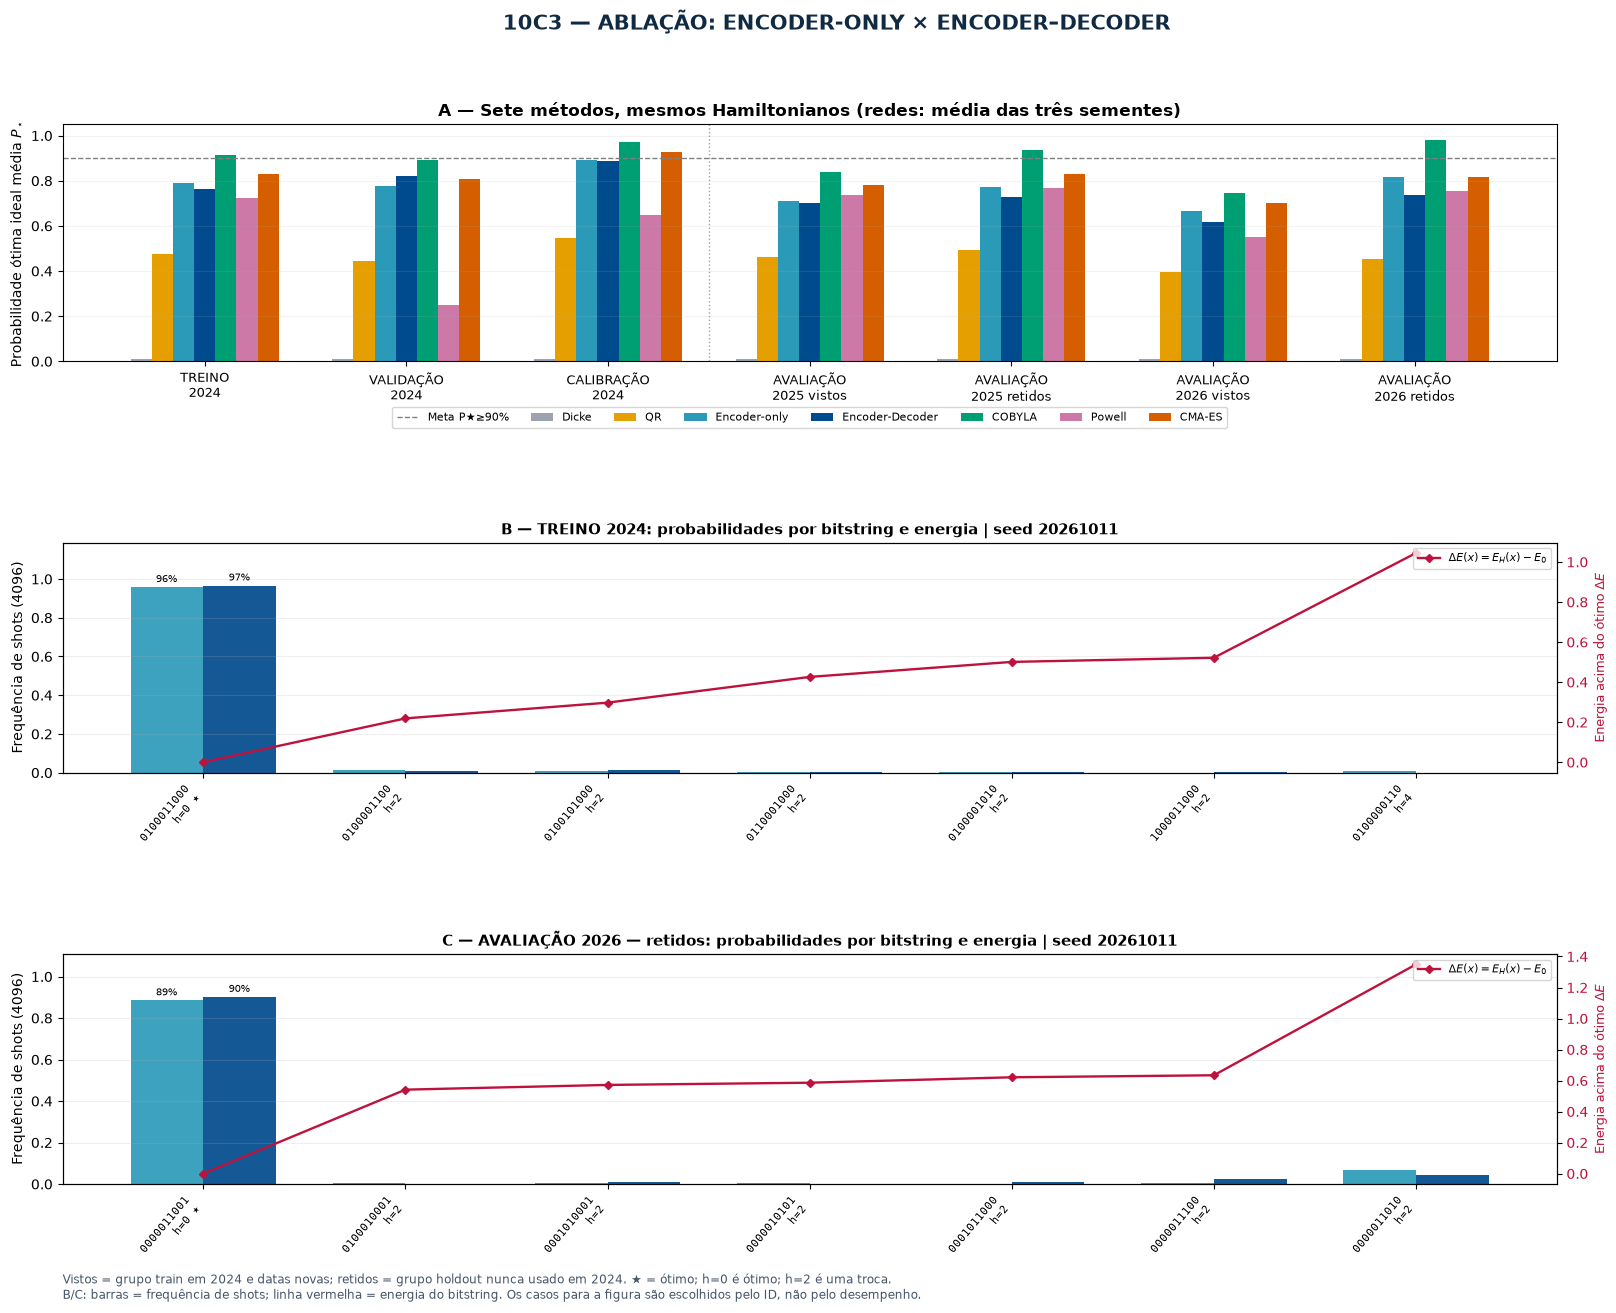

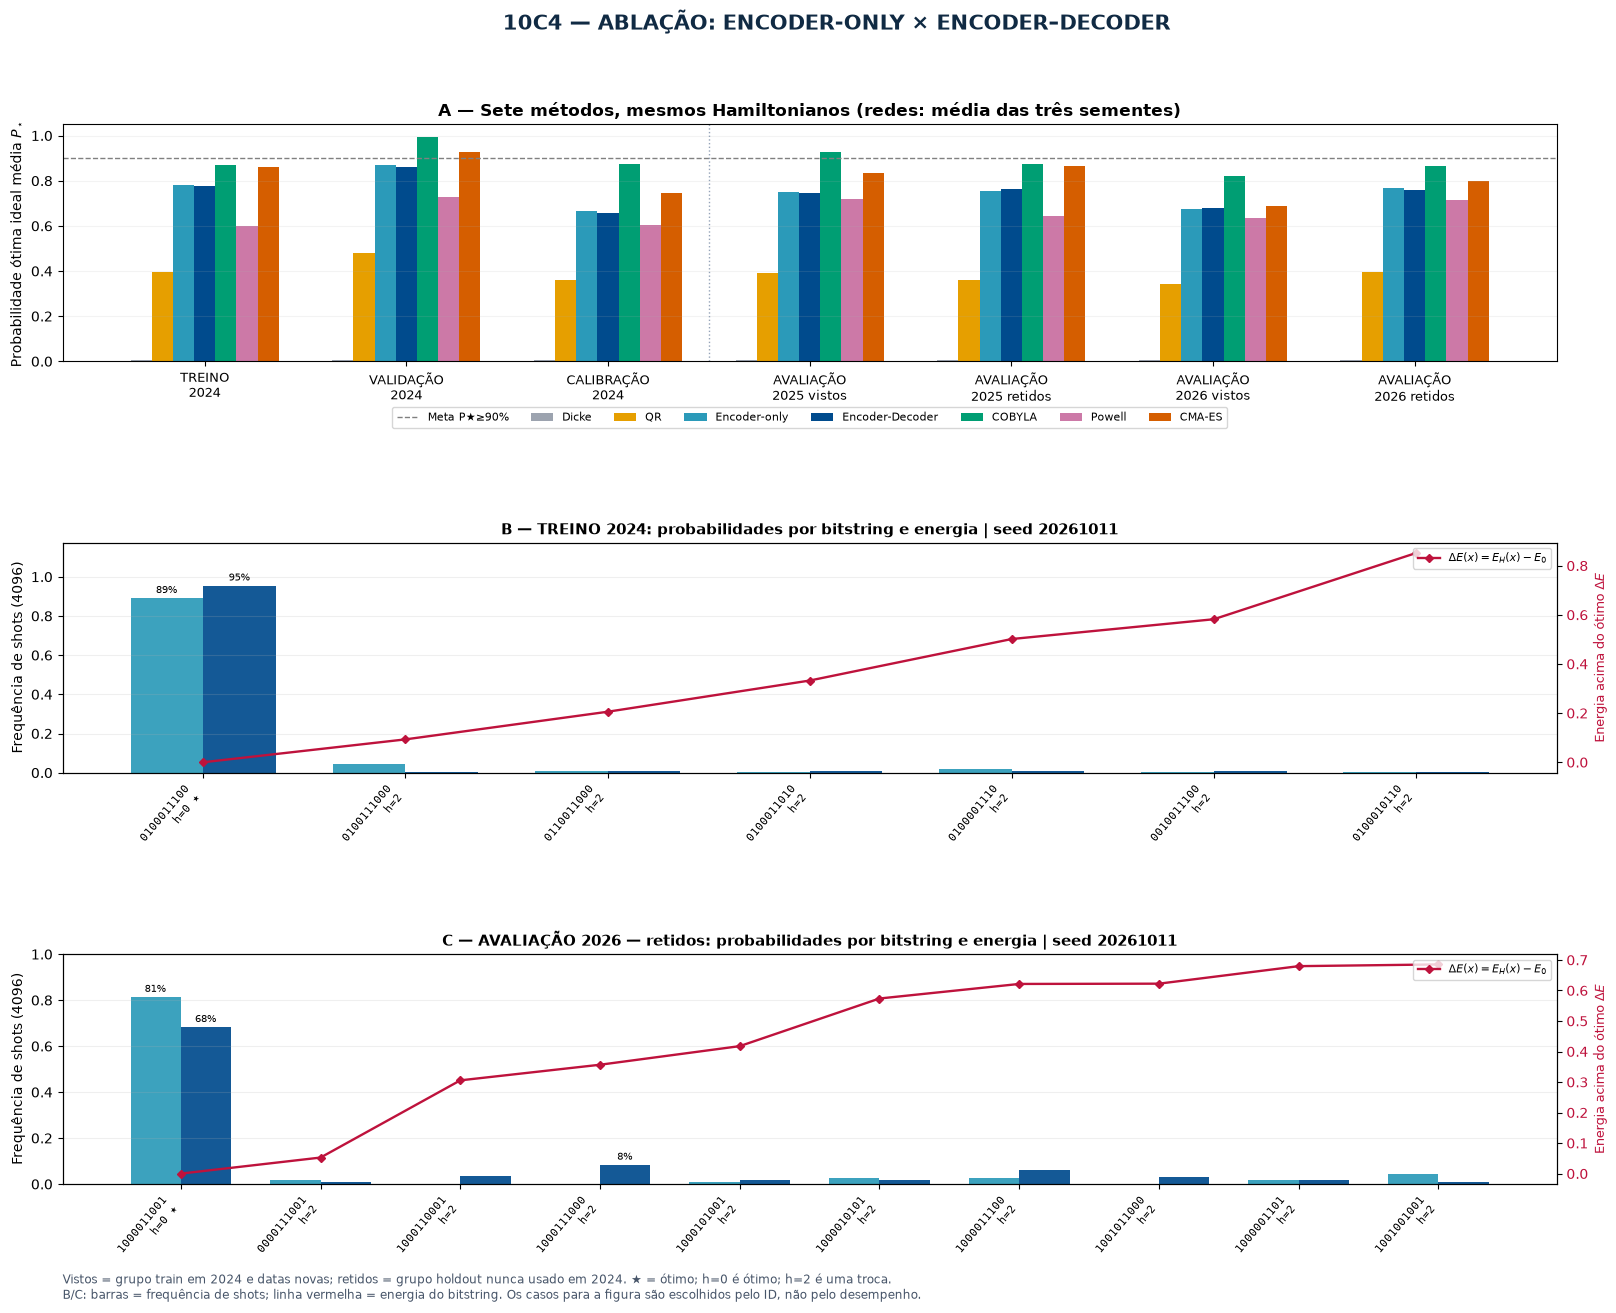

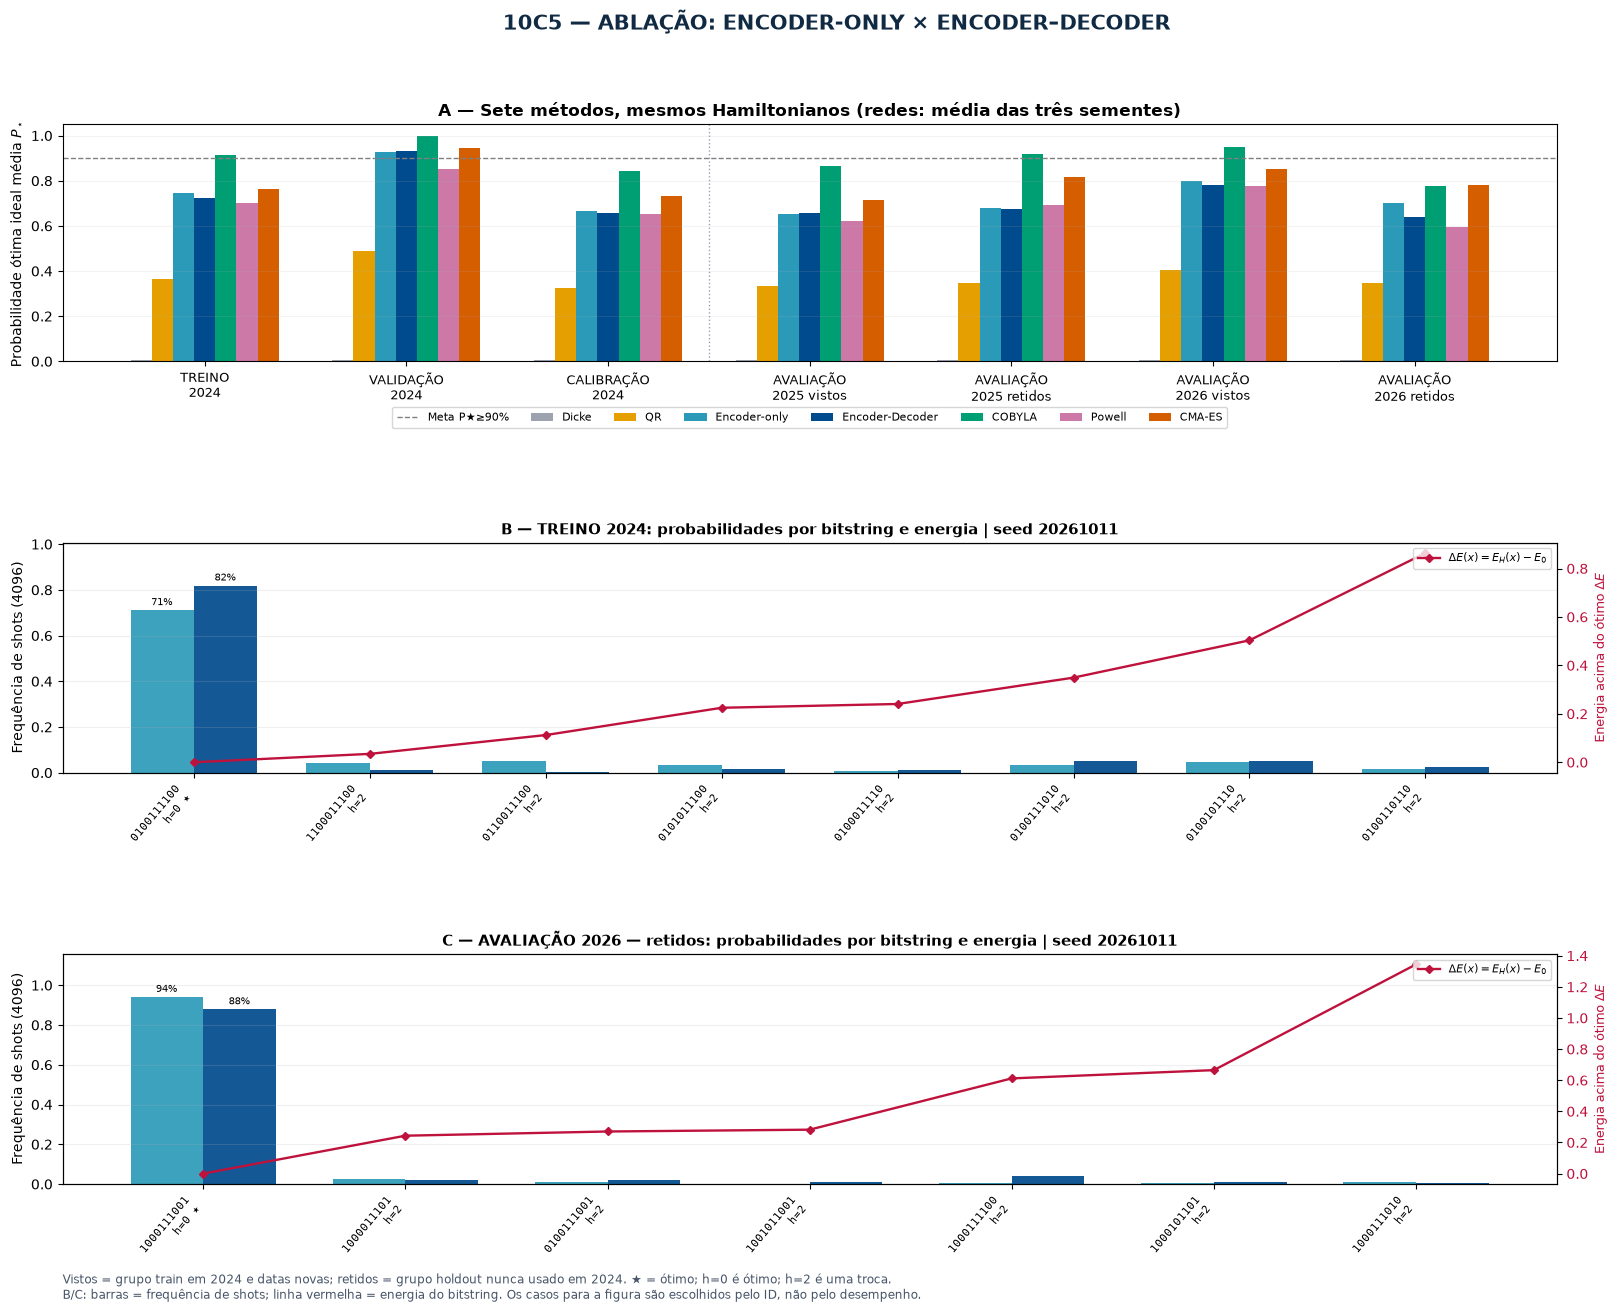

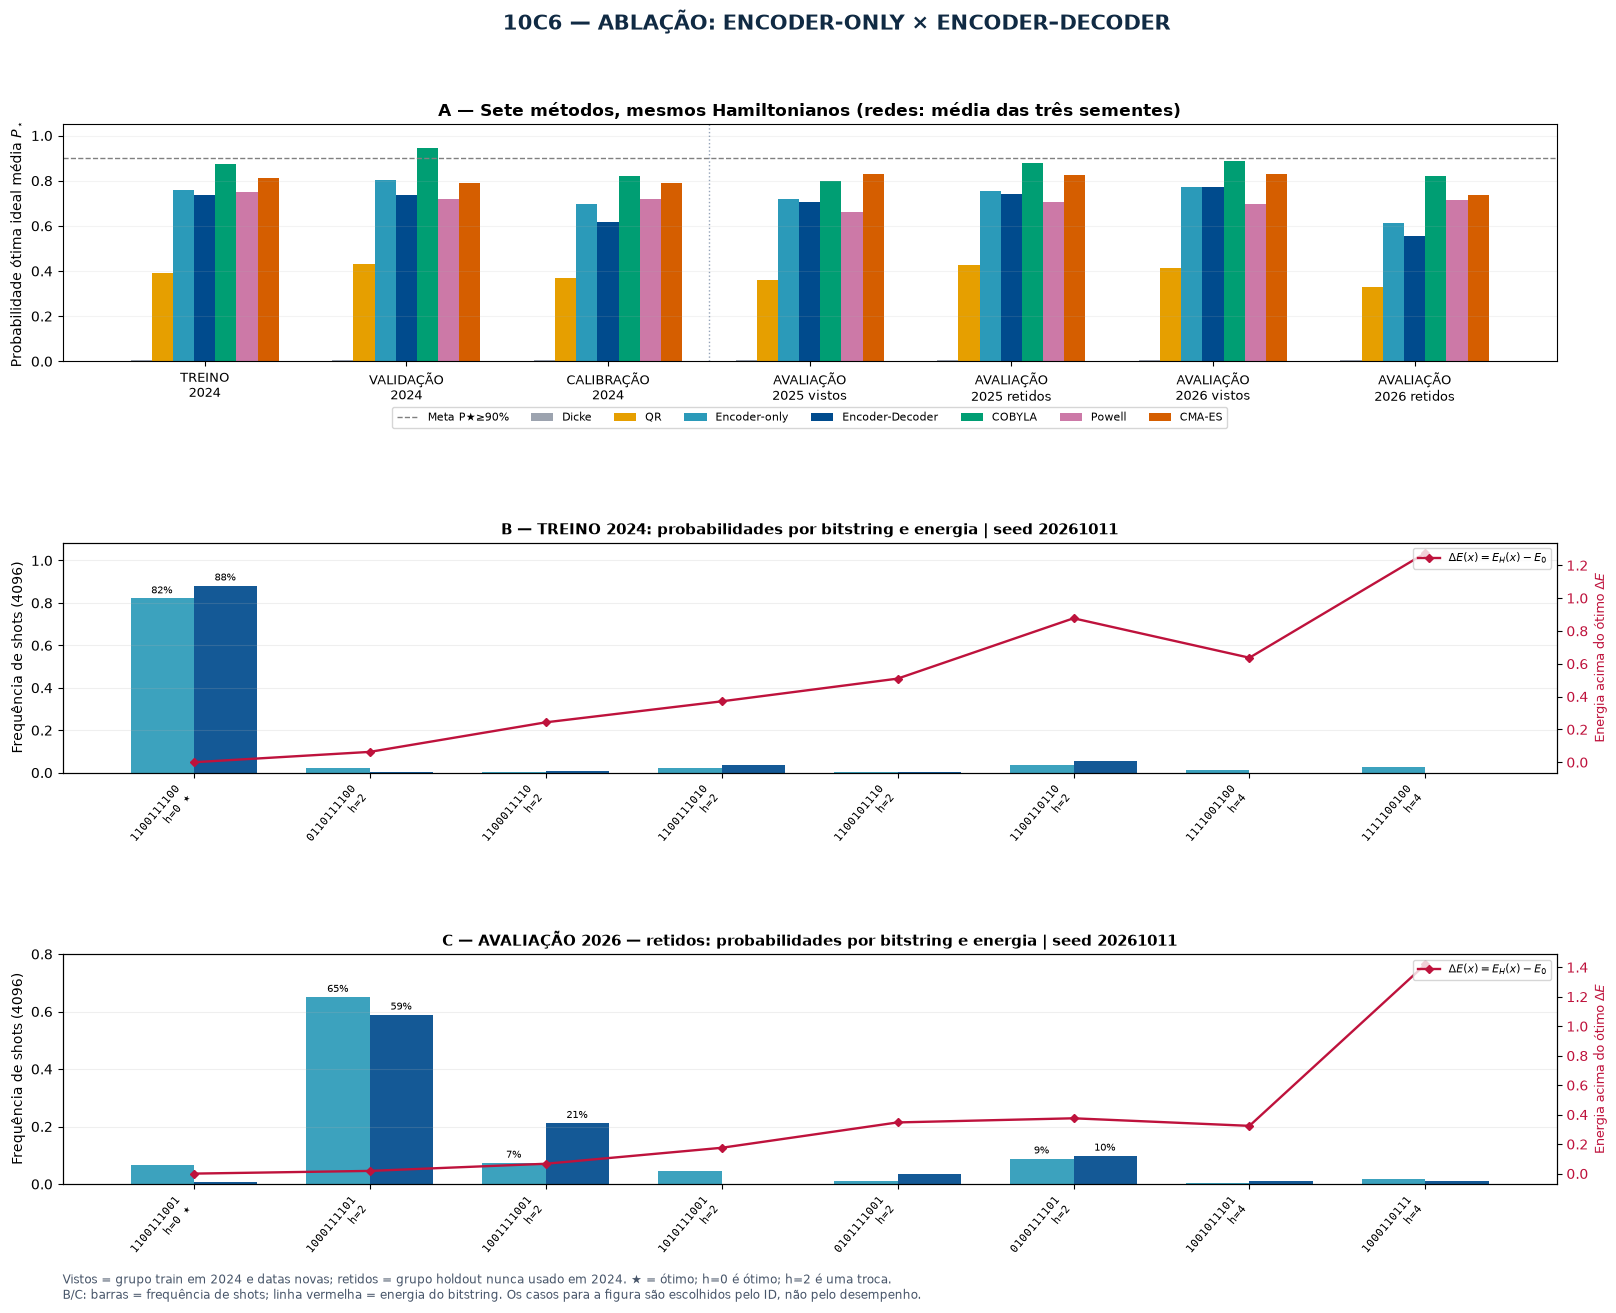

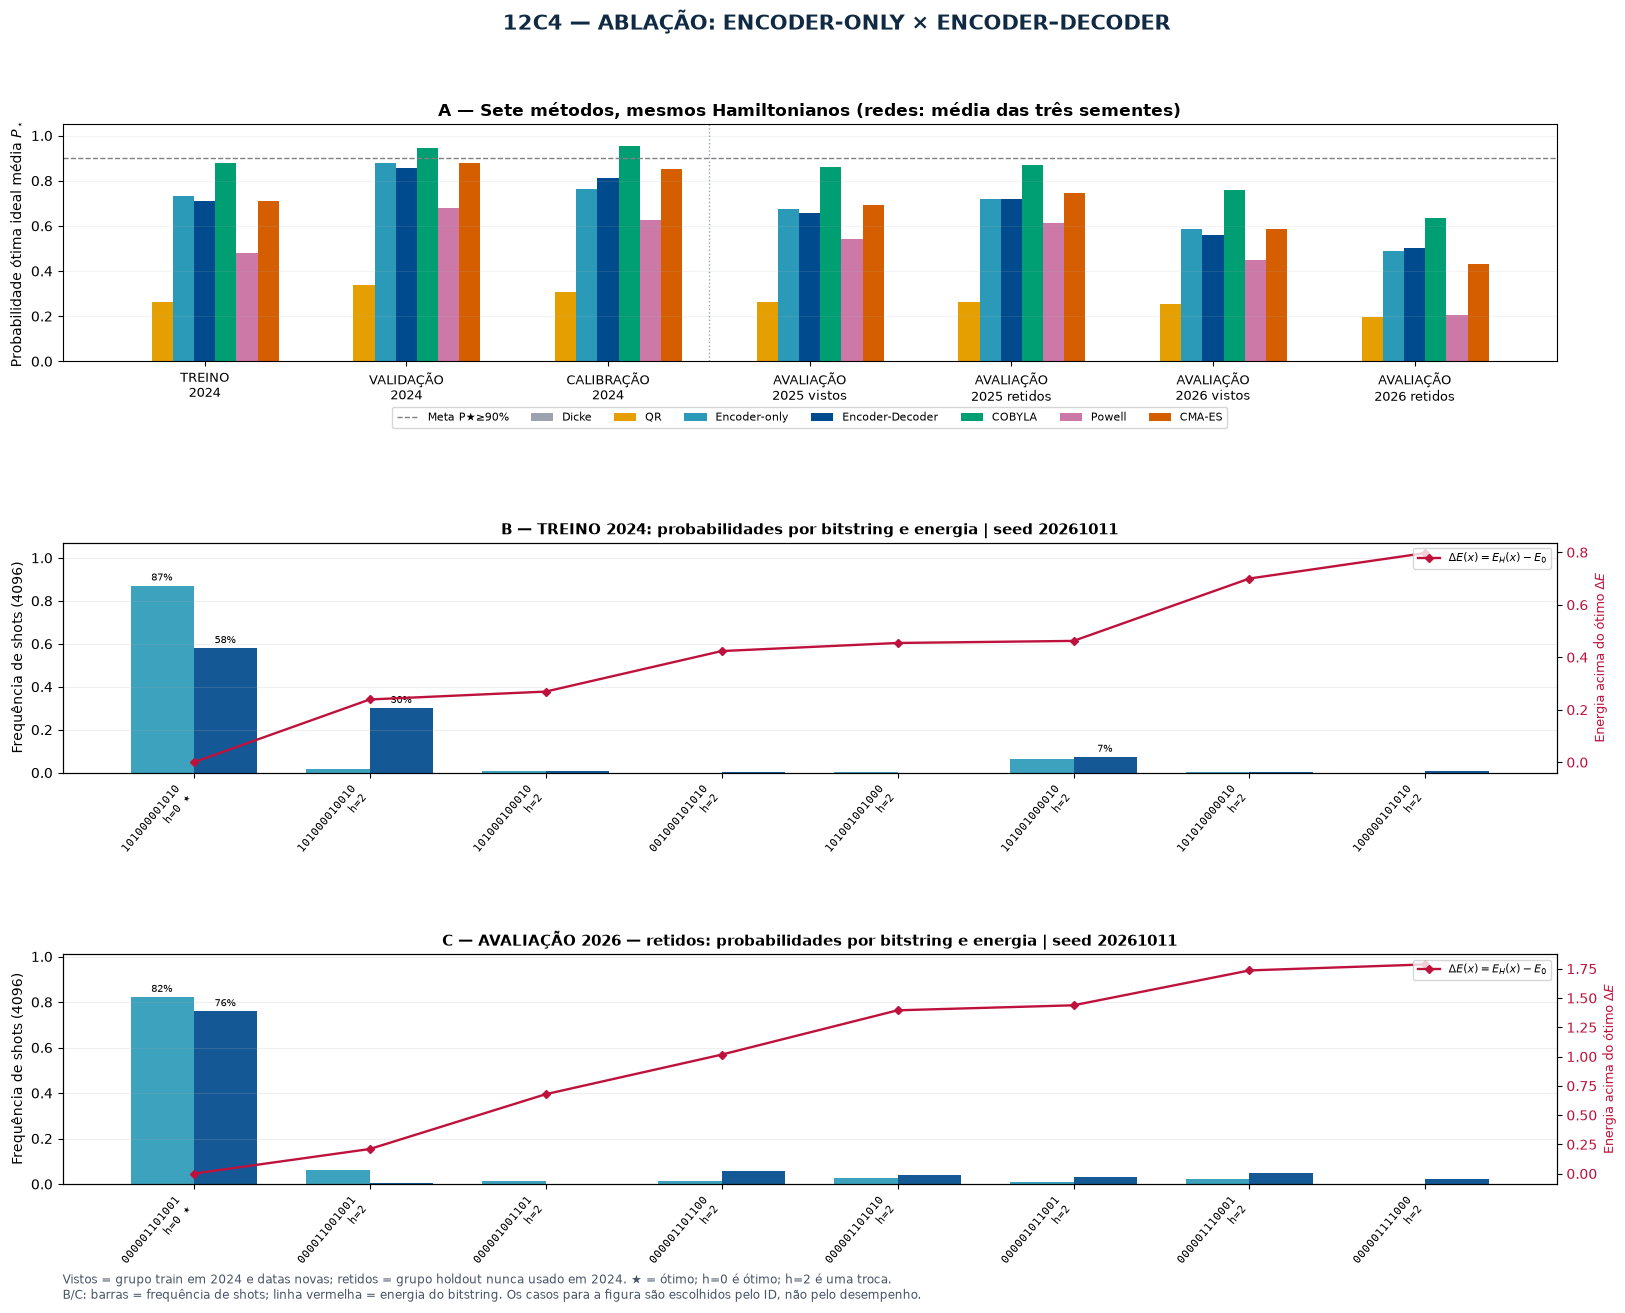

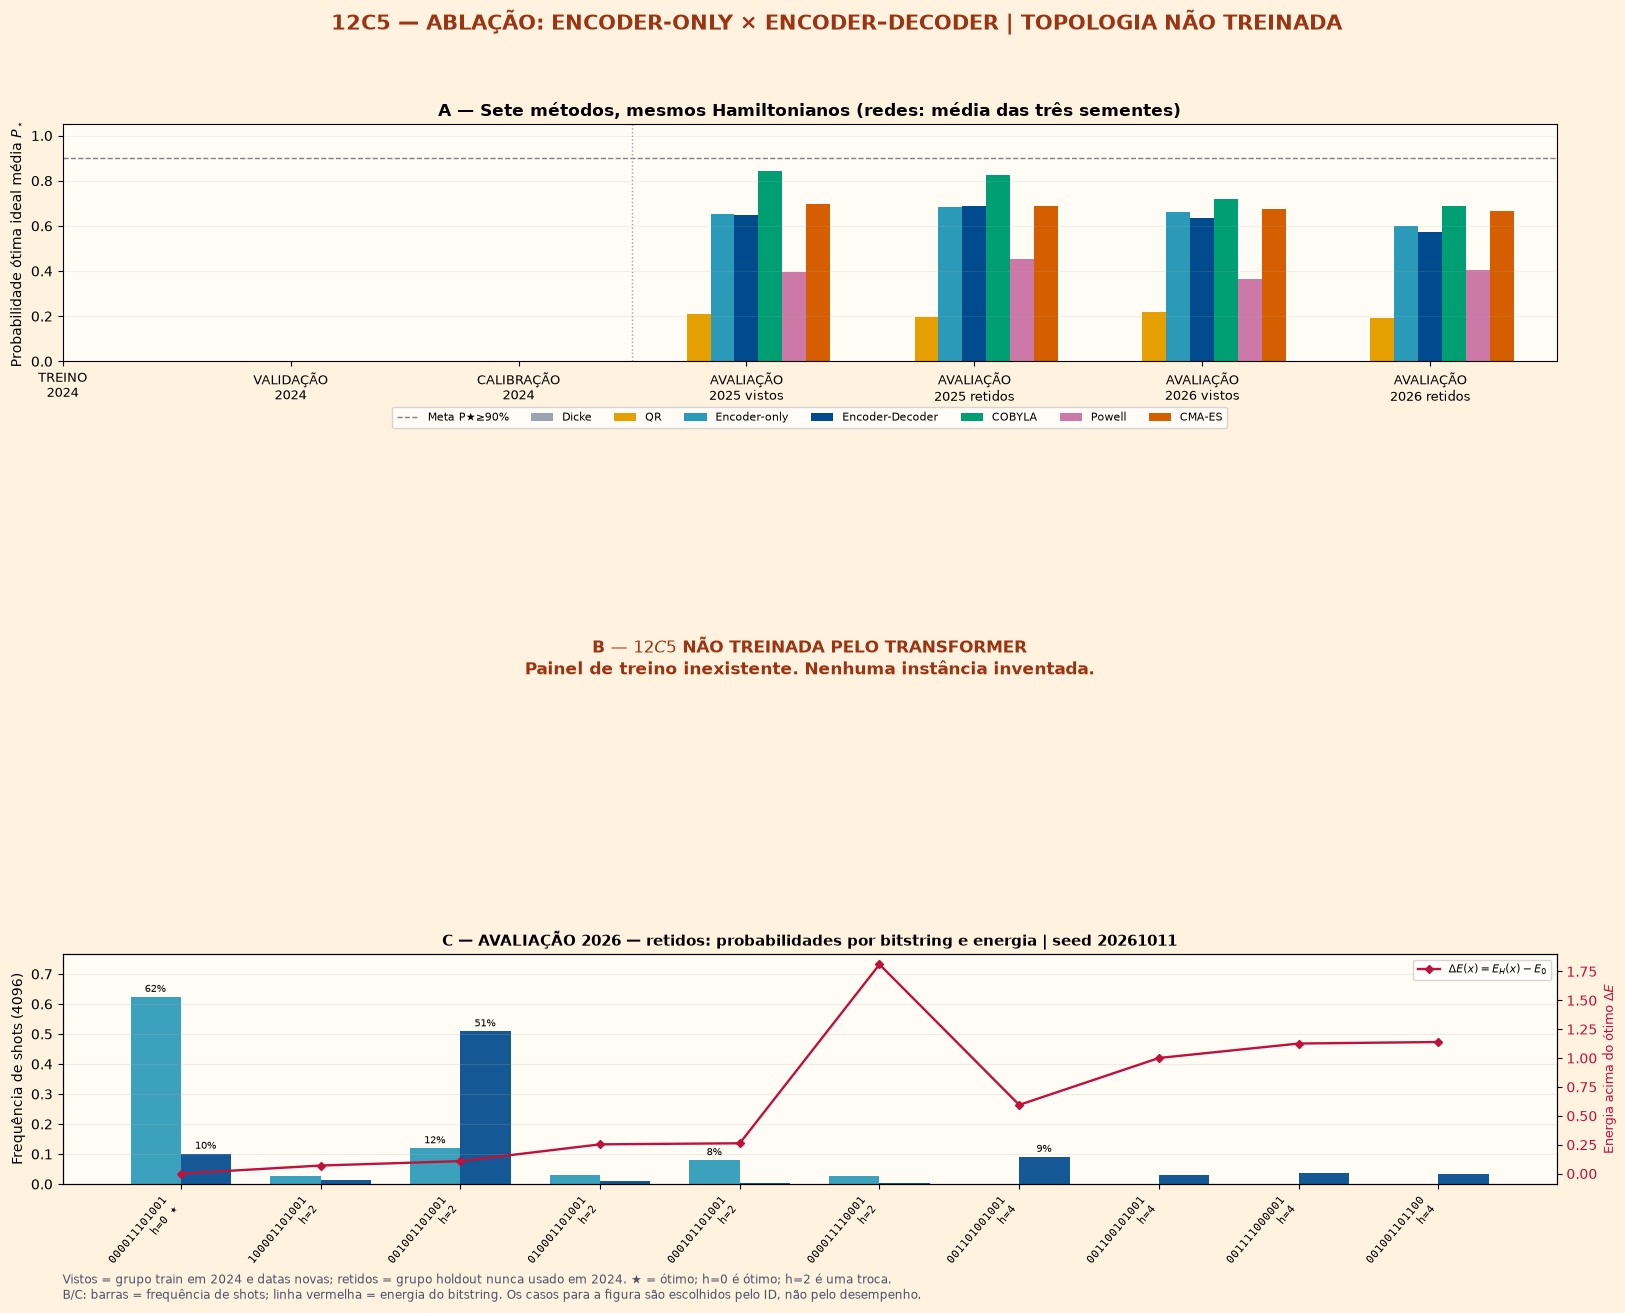

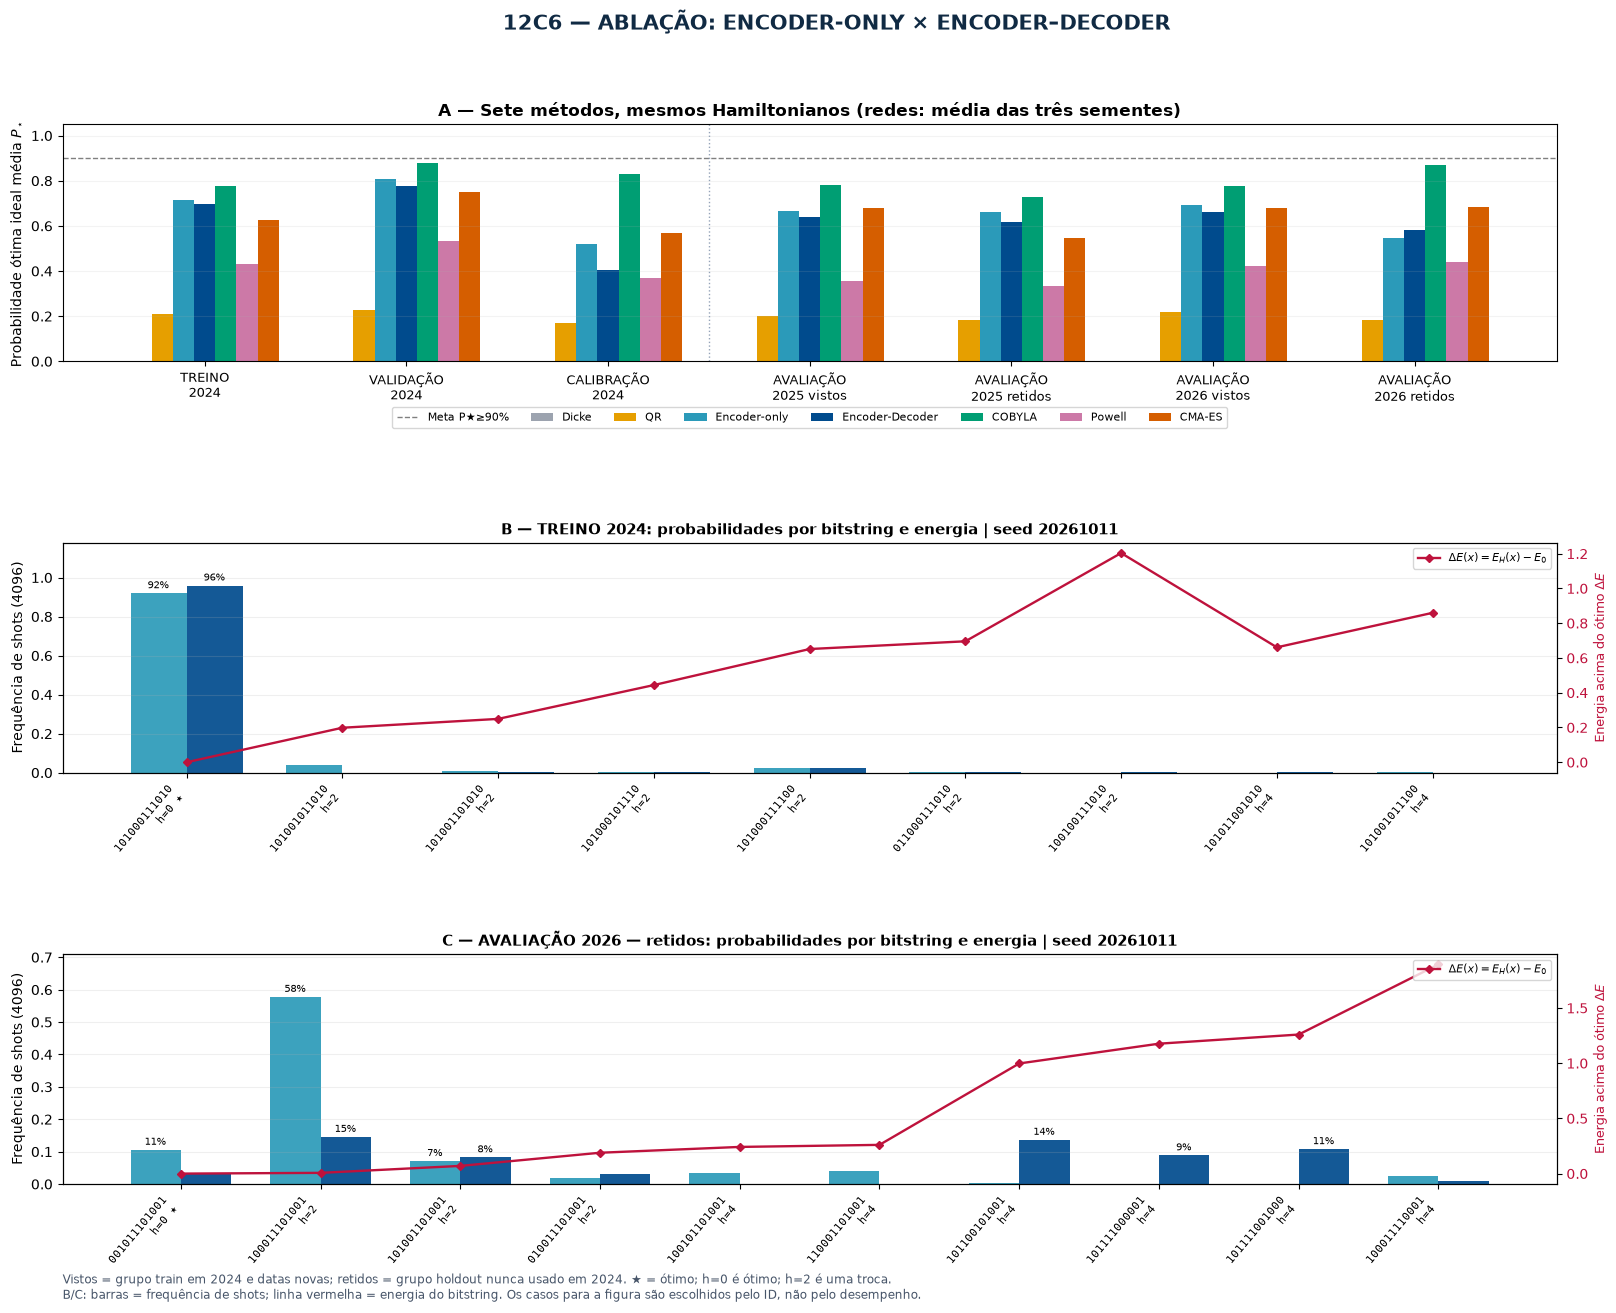

Exatamente sete figuras em /home/marlonmaxuel/Desktop/g53_encdec_vs_enconly_2024_2026/RESUMO_7_TOPOLOGIAS


In [15]:
# Only seven composite figures total — no figures per instance or per month.
FIG_SPECS=['10C3','10C4','10C5','10C6','12C4','12C5','12C6']
FIG_STAGES=[
    ('TREINO\n2024','TREINO 2024',None),
    ('VALIDAÇÃO\n2024','VALIDAÇÃO 2024',None),
    ('CALIBRAÇÃO\n2024','CALIBRAÇÃO 2024',None),
    ('AVALIAÇÃO\n2025 vistos','AVALIAÇÃO 2025','train'),
    ('AVALIAÇÃO\n2025 retidos','AVALIAÇÃO 2025','holdout'),
    ('AVALIAÇÃO\n2026 vistos','AVALIAÇÃO 2026','train'),
    ('AVALIAÇÃO\n2026 retidos','AVALIAÇÃO 2026','holdout'),
]


def select_panel_id(metrics,spec,training):
    q=metrics[metrics['spec'].eq(spec)]
    if training:
        ids=sorted(q.loc[q['dataset_label'].eq('TREINO 2024'),'id'].unique().tolist())
        return (ids[0],'TREINO 2024') if ids else (None,None)
    for lab,group in [('AVALIAÇÃO 2026','holdout'),('AVALIAÇÃO 2025','holdout'),
                      ('AVALIAÇÃO 2026','train'),('AVALIAÇÃO 2025','train')]:
        sub=q[q['dataset_label'].eq(lab)&q['group'].eq(group)]
        ids=sorted(sub['id'].unique().tolist())
        if ids:return ids[0],f'{lab} — {"retidos" if group=="holdout" else "vistos"}'
    return None,None


def plot_bits(ax,bitstrings,record_id,spec,title):
    # Same seed, same portfolio/Hamiltonian for two architectures.
    sel=bitstrings[bitstrings['id'].eq(record_id)&
                   bitstrings['spec'].eq(spec)&
                   bitstrings['method'].isin(NN_METHODS)&
                   bitstrings['model_seed'].eq(TRAIN_SEEDS[0])].copy()
    if sel.empty:
        raise RuntimeError('Nenhum bitstring medido no caso predefinido')
    n=int(spec.split('C')[0])
    sel['bitstring']=sel['bitstring'].astype(str).str.zfill(n)
    # Set of displayed bitstrings: all measured oracles + 6 most frequent for each architecture.
    candidates=set(sel.loc[sel['is_oracle'].eq(1),'bitstring'])
    for method in NN_METHODS:
        candidates.update(sel.loc[sel['method'].eq(method)].nlargest(6,'frequency')['bitstring'])
    data=(sel.drop_duplicates('bitstring').set_index('bitstring')
          .loc[lambda d:d.index.isin(candidates)]
          .sort_values(['Hamming','deltaE'],ascending=[True,True]))
    ordered=list(data.index)[:16]
    data=data.loc[ordered]
    pivot=sel.pivot_table(index='bitstring',columns='method',values='frequency',
                          aggfunc='sum',fill_value=0).reindex(index=ordered,
                          columns=NN_METHODS,fill_value=0)
    H=data['Hamming'].to_numpy(int)
    de=data['deltaE'].to_numpy(float)
    x=np.arange(len(ordered),dtype=float)
    width=.36
    for j,method in enumerate(NN_METHODS):
        vals=pivot[method].to_numpy(float)
        bars=ax.bar(x+(j-.5)*width,vals,width=width,color=COLORS[method],
                    alpha=.92,label=method)
        for rect,val in zip(bars,vals):
            if val>=.07:
                ax.annotate(f'{100*val:.0f}%',xy=(rect.get_x()+rect.get_width()/2,
                    rect.get_height()),xytext=(0,2),textcoords='offset points',
                    ha='center',va='bottom',fontsize=7)
    oracle=set(sel.loc[sel['is_oracle'].eq(1),'bitstring'])
    ax.set_xticks(x,[b+f'\nh={h}'+(' ★' if b in oracle else '')
                     for b,h in zip(ordered,H)],rotation=50,ha='right',
                    fontsize=8,fontfamily='monospace')
    ax.set_ylabel('Frequência de shots (4096)')
    ax.set_ylim(0,max(.12,float(pivot.to_numpy(float).max())*1.23))
    ax.grid(axis='y',alpha=.2)
    ax.set_title(title+' | seed '+str(TRAIN_SEEDS[0]),fontsize=11,fontweight='bold')
    energy_axis=ax.twinx()
    energy_axis.plot(x,de,color='#be123c',marker='D',lw=1.7,ms=4,
                     label='$\\Delta E(x)=E_H(x)-E_0$')
    energy_axis.set_ylim(bottom=-max(.001,float(de.max())*.05))
    energy_axis.set_ylabel('Energia acima do ótimo $\\Delta E$',color='#be123c',fontsize=9)
    energy_axis.tick_params(axis='y',labelcolor='#be123c')
    energy_axis.legend(loc='upper right',fontsize=8)


def render_topology_figures(metrics,bitstrings,output):
    path=Path(output)/'RESUMO_7_TOPOLOGIAS'
    path.mkdir(parents=True,exist_ok=True)
    outputs=[];summary=[]
    for spec in FIG_SPECS:
        if spec not in set(metrics['spec']):raise RuntimeError(f'Sem resultados para {spec}')
        fig=plt.figure(figsize=(18,13.5))
        gs=fig.add_gridspec(3,1,height_ratios=[1.03,1,1],left=.07,right=.90,
                            top=.90,bottom=.115,hspace=.78)
        ax=fig.add_subplot(gs[0]);axtrain=fig.add_subplot(gs[1]);axeval=fig.add_subplot(gs[2])
        if spec=='12C5':
            fig.patch.set_facecolor('#fff2df')
            for a in (ax,axtrain,axeval):a.set_facecolor('#fffbf5')
        xpos=np.arange(len(FIG_STAGES),dtype=float)
        width=.105
        for j,method in enumerate(METHODS):
            y=[]
            for shown,split,group in FIG_STAGES:
                s=metrics[metrics['spec'].eq(spec)&metrics['method'].eq(method)&
                          metrics['dataset_label'].eq(split)]
                if group is not None:s=s[s['group'].eq(group)]
                mean=float(s['Pstar'].mean()) if len(s) else np.nan
                summary.append({'spec':spec,'stage':shown,'method':method,
                                'n_hamiltonians':int(s['id'].nunique()),
                                'n_runs':len(s),'Pstar_mean':mean})
                y.append(mean)
            ax.bar(xpos+(j-(len(METHODS)-1)/2)*width,y,width=width,
                   color=COLORS[method],label=method)
        ax.axhline(.9,color='gray',ls='--',lw=1,label='Meta P★≥90%')
        ax.axvline(2.5,color='#94a3b8',ls=':',lw=1)
        ax.set_ylim(0,1.05)
        ax.set_ylabel('Probabilidade ótima ideal média $P_\\star$')
        ax.set_xticks(xpos,[x[0] for x in FIG_STAGES],fontsize=9)
        ax.set_title('A — Sete métodos, mesmos Hamiltonianos (redes: média das três sementes)',
                     fontsize=12,fontweight='bold')
        ax.legend(ncol=8,fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.17))
        ax.grid(axis='y',alpha=.15)
        rid,lab=select_panel_id(metrics,spec,True)
        if rid is None:
            axtrain.axis('off')
            axtrain.text(.5,.5,'B — $12C5$ NÃO TREINADA PELO TRANSFORMER\n'
                'Painel de treino inexistente. Nenhuma instância inventada.',
                transform=axtrain.transAxes,ha='center',va='center',fontsize=12,
                color='#9a3412',fontweight='bold')
        else:plot_bits(axtrain,bitstrings,rid,spec,'B — TREINO 2024: probabilidades por bitstring e energia')
        rid,lab=select_panel_id(metrics,spec,False)
        if rid is None:
            axeval.axis('off');axeval.text(.5,.5,'Sem instância de avaliação',
                                          transform=axeval.transAxes,ha='center',va='center')
        else:plot_bits(axeval,bitstrings,rid,spec,'C — '+lab+': probabilidades por bitstring e energia')
        fig.suptitle(spec+' — ABLAÇÃO: ENCODER-ONLY × ENCODER–DECODER'
                     + (' | TOPOLOGIA NÃO TREINADA' if spec=='12C5' else ''),
                     fontsize=15,fontweight='bold',y=.985,
                     color='#9a3412' if spec=='12C5' else '#102a43')
        fig.text(.07,.03,'Vistos = grupo train em 2024 e datas novas; retidos = grupo holdout nunca usado em 2024. '
                '★ = ótimo; h=0 é ótimo; h=2 é uma troca.\n'
                'B/C: barras = frequência de shots; linha vermelha = energia do bitstring. '
                'Os casos para a figura são escolhidos pelo ID, não pelo desempenho.',
                fontsize=8.5,color='#475569')
        dest=path/f'{spec}_ENCODER_VS_DECODER_HAMMING_ENERGIA.png'
        fig.savefig(dest,dpi=155,bbox_inches='tight')
        display(fig)
        plt.close(fig)
        outputs.append(dest)
    assert len(outputs)==7
    pd.DataFrame(summary).to_csv(path/'resumo_sete_metodos_por_topologia.csv',index=False)
    print('Exatamente sete figuras em',path)
    return outputs

SETE_FIGURAS=render_topology_figures(METRICS,BITSTRINGS,OUT)


## 16 — Dados completos, sem multiplicar gráficos

Os arquivos `metrics_all_splits.csv` e `bitstrings_all_splits.csv` guardam **todas as avaliações** e medições, incluindo os seis métodos, todas as datas e cada bitstring observado. O gráfico consolidado apenas mostra **um caso fixado antes de consultar o resultado**, separadamente no treino e na avaliação, para explicar o mecanismo sem gerar centenas de figuras. Para todos os casos, utilize os CSVs e não imagens individuais.

No painel de bitstrings, as barras representam apenas o **Transformer**. Os seis métodos seguem comparados no **painel superior** de cada figura e permanecem nos CSVs. A energia da linha vermelha é o valor real de $\Delta E(x)$, não um número reescalado para acompanhar o Hamming.

In [16]:
print('Visualização concluída: somente 7 figuras, com treino/avaliação e energia por bitstring.')
print('CSV de todas as medidas:', OUT/'bitstrings_all_splits.csv')
print('Figuras consolidadas:', OUT/'RESUMO_7_TOPOLOGIAS')

Visualização concluída: somente 7 figuras, com treino/avaliação e energia por bitstring.
CSV de todas as medidas: /home/marlonmaxuel/Desktop/g53_encdec_vs_enconly_2024_2026/bitstrings_all_splits.csv
Figuras consolidadas: /home/marlonmaxuel/Desktop/g53_encdec_vs_enconly_2024_2026/RESUMO_7_TOPOLOGIAS


## 17 — Análise pareada, incerteza, orçamento e interpretação científica

A hipótese é decidida prioritariamente pela diferença **encoder–decoder menos encoder-only**, pareada por **identificador do mesmo Hamiltoniano e pela mesma semente**:

$$
\underbrace{\Delta P_\star(r,s)}_{\substack{\downarrow\\\text{vantagem da cross-attention}}}
=\underbrace{P_\star^{\mathrm{EncDec}}(r,s)}_{\substack{\downarrow\\\text{modelo proposto}}}-\underbrace{P_\star^{\mathrm{EncOnly}}(r,s)}_{\substack{\downarrow\\\text{controle com mesmas informações}}}.
$$

Da mesma forma registramos $\Delta\eta_E$ para energia normalizada e $\Delta d_H$ para Hamming. A média sobre instâncias é descrita, mas **não** tratamos janelas, datas, cardinalidades e sementes como amostras financeiramente independentes. Agregamos diferenças primeiro por universo e semente e produzimos intervalos por *bootstrap de universos* (com aviso quando existirem poucos universos).

O encoder–decoder só apresentará evidência forte de vantagem se a melhoria for **pareada, persistente nas topologias e sementes, e robusta nos ativos retidos**. Reduzir a loss de treino sem melhorar o teste não valida a hipótese. Comparações com COBYLA e CMA-ES devem relatar orçamento e pré-processamento.

O $12C5$ representa **interpolação estrutural** para um número de qubits já visto ($n=12$), não extrapolação irrestrita. O espectro energético completo já é usado na geometria QR, e por isso a experiência **não prova vantagem computacional quântica**.

In [17]:
# 1. Raw summary; model seeds remain in the raw CSV and n_instances is unique.
SUMMARY=(METRICS.groupby(['dataset_label','group','spec','method'],dropna=False)
    .agg(n_hamiltonians=('id','nunique'),n_executions=('id','size'),
         Pstar=('Pstar','mean'),success90=('success90','mean'),
         energy_error=('energy_error','mean'),Hamming=('hamming_mean','mean'),
         Pstar_shots=('Pstar_shots','mean'),
         circuit_evals=('circuit_evaluations','mean'),
         CP_coverage=('cp_coverage','mean'),CP_size=('cp_size','mean'))
    .reset_index())
SUMMARY.to_csv(OUT/'summary_by_split_spec_method.csv',index=False)

# 2. Real paired comparison: one (Hamiltonian, seed) matches one run in each model.
network_rows=METRICS[METRICS['method'].isin(NN_METHODS)].copy()
index_cols=['id','model_seed','split','group','universe','spec','dataset_label']
wide=network_rows.pivot_table(index=index_cols,columns='method',
    values=['Pstar','energy_error','hamming_mean','Pstar_shots','cp_coverage'],
    aggfunc='first')
for metric in ['Pstar','energy_error','hamming_mean','Pstar_shots','cp_coverage']:
    assert (metric,'Encoder-Decoder') in wide and (metric,'Encoder-only') in wide
    wide[('delta_'+metric,'PAIR')]=wide[(metric,'Encoder-Decoder')]-wide[(metric,'Encoder-only')]
paired=wide.reset_index()
paired.columns=['__'.join(str(v) for v in col if str(v) not in ('','None'))
                if isinstance(col,tuple) else str(col) for col in paired.columns]
assert len(paired)==len(TRAIN_SEEDS)*sum(map(len,SPLITS.values()))
paired.to_csv(OUT/'encoder_decoder_versus_encoder_only_pareado.csv',index=False)

# 3. Cluster bootstrap: cluster = group + universe identifier, averaged across
# time windows, cardinalities, and paired seeds first. Few clusters -> descriptive.
cluster_results=[]
rng_boot=np.random.default_rng(SEED+477)
for (dataset_label,group,spec),d in paired.groupby(
        ['dataset_label','group','spec'],dropna=False):
    # In the same n and k, universe ID is stable across dates/windows.
    cluster=d.groupby('universe')['delta_Pstar__PAIR'].mean().to_numpy(float)
    center=float(np.mean(cluster))
    nclusters=len(cluster)
    if nclusters>=3:
        draws=rng_boot.choice(cluster,size=(2000,nclusters),replace=True).mean(axis=1)
        low,high=np.quantile(draws,[.025,.975]);interval='bootstrap_clusters_exploratorio'
    else:
        low=high=np.nan;interval='insuficiente_clusters_independentes'
    cluster_results.append({'dataset_label':dataset_label,'group':group,'spec':spec,
        'n_clusters':nclusters,'n_hamiltonianos':d['id'].nunique(),
        'n_seeds':d['model_seed'].nunique(),'deltaPstar_EncDec_menos_EncOnly':center,
        'ci95_cluster_low':low,'ci95_cluster_high':high,'intervalo':interval,
        'deltaEnergy':float(d['delta_energy_error__PAIR'].mean()),
        'deltaHamming':float(d['delta_hamming_mean__PAIR'].mean()),
        'deltaPstar_shots':float(d['delta_Pstar_shots__PAIR'].mean())})
CLUSTER_SUMMARY=pd.DataFrame(cluster_results)
CLUSTER_SUMMARY.to_csv(OUT/'diferencas_pareadas_intervalos_por_universo.csv',index=False)
print('\nCOMPARAÇÃO PAREADA — 2025/26, grupos retidos')
print(CLUSTER_SUMMARY.loc[CLUSTER_SUMMARY['group'].eq('holdout') &
    CLUSTER_SUMMARY['dataset_label'].str.startswith('AVALIAÇÃO')].to_string(index=False))

PROVENANCE={
    'implementation':'G5.3, PyTorch NN / Qiskit circuits only',
    'qiskit_version':__import__('qiskit').__version__,
    'torch_version':torch.__version__,
    'train_year':2024,'train_specs':TRAIN_SPECS,'heldout_spec':HELDOUT,
    'train_seeds':TRAIN_SEEDS,'epochs':EPOCHS,'SPSA_directions':SPSA_DIRECTIONS,
    'params':PARAMETERS,'param_gap_fraction':PARAM_GAP,
    'optimizer_budget_each':OPT_BUDGET,'shots':SHOTS,
    'n_hamiltonians':sum(map(len,SPLITS.values())),
    'n_metric_rows':len(METRICS),'qiskit_calls_total':sum(c.calls for c in CIRC.values()),
    'plot_count':len(SETE_FIGURAS),'checkpoint_val_2024':{
        f'{name}|{seed}':v for (name,seed),v in BEST_2024.items()},
    'conformal_2024':CP_INFO,
    'full_energy_spectrum_preprocessing':True,
    'note':'Exact classical oracle of feasible energy is computed; no quantum speedup claim.',
}
(OUT/'proveniencia_g53.json').write_text(json.dumps(PROVENANCE,indent=2,ensure_ascii=False,default=str))
assert len(SETE_FIGURAS)==7
assert HELDOUT not in {r['spec'] for r in TRAIN+VAL+CAL}
print('\nG5.3 concluído. Outputs:',OUT)



COMPARAÇÃO PAREADA — 2025/26, grupos retidos
 dataset_label   group spec  n_clusters  n_hamiltonianos  n_seeds  deltaPstar_EncDec_menos_EncOnly  ci95_cluster_low  ci95_cluster_high                           intervalo  deltaEnergy  deltaHamming  deltaPstar_shots
AVALIAÇÃO 2025 holdout 10C3           2               16        3                        -0.044271               NaN                NaN insuficiente_clusters_independentes     0.010273      0.129672         -0.043676
AVALIAÇÃO 2025 holdout 10C4           2               16        3                         0.007713               NaN                NaN insuficiente_clusters_independentes     0.002207     -0.016324          0.008484
AVALIAÇÃO 2025 holdout 10C5           2               16        3                        -0.005312               NaN                NaN insuficiente_clusters_independentes    -0.000734      0.007851         -0.006841
AVALIAÇÃO 2025 holdout 10C6           2               16        3                     